# 17 · Frequency-Bin QKD from Ring Sources: Reproduce, Send a Message, Design

**Question:** can a simple rate model reproduce two published frequency-bin entanglement-based QKD experiments? Can it send a real message with a simulated key? And how do ring design and receiver set key rate, range and usable dimension?

**Experiments:**
- **E2025**, Crisan et al., [arXiv:2507.00972](https://arxiv.org/abs/2507.00972): silicon ring, FSR 21.23 GHz, Q 4.75 × 10⁵, CW pump, 21 channels, qubits and qutrits.
- **E2024**, Tagliavacche et al., [arXiv:2411.07884](https://arxiv.org/abs/2411.07884): two silicon rings, bins 15 GHz apart, Q about 10⁵, up to 26 km of fibre.

**Answer in advance:**
- Three numbers **fitted** on one E2025 operating point **predict** the range (58.4 vs 59 dB) and the heralded g⁽²⁾ (0.078 vs 0.077). They **miss** the qutrit QBER by about 30 %, and the qutrit key rate agrees only because two errors cancel. All of this is shown below.
- "Hello Kues group" travels on a Monte Carlo BBM92 key with Cascade and Toeplitz hashing; an intercept-resend eavesdropper is detected.
- **Design rule:** do not maximise Q. **Receivers:** bias the bases first; a full Fourier sorter adds little at 25 km and helps at 150 km.

All key rates are **asymptotic**. Any rate below 1 bit/s is labelled "asymptotic only".

```
rate model + QuTiP check ─▶ fit on E2025 ─▶ predictions and misses ─▶ E2024 ─▶ BBM92 message and Eve ─▶ ring design ─▶ receivers
```

In [1]:
import numpy as np
import qutip as qt
import json, os, time, hashlib, io, contextlib
from dataclasses import dataclass, replace
from typing import Callable, Optional
from scipy.integrate import quad
from scipy.linalg import toeplitz
from scipy.optimize import brentq, fsolve
from scipy.signal import fftconvolve
from scipy.special import erfc, erfcx, jnp_zeros, jv, voigt_profile
from scipy.stats import binom
import matplotlib.pyplot as plt

results, predictions = [], []
t_start = time.time()

def check(label, sim, ref, tol=1e-3, rel=False):
    """Compare a number with an independent value and record the result."""
    sim, ref = float(np.real(sim)), float(np.real(ref))
    err = abs(sim - ref) / abs(ref) if rel else abs(sim - ref)
    ok = bool(err <= tol)
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: model = {sim:.6g}, check = {ref:.6g}")

def check_sigma(label, sim, model, n, nsig=3.0):
    """Statistical test at nsig standard errors. With many such tests in one notebook, 3 sigma keeps the overall false-alarm rate near 5 %."""
    s = np.sqrt(model * (1 - model) / n)
    ok = bool(abs(sim - model) <= nsig * s)
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: MC = {sim:.5f}, model = {model:.5f}, off by {(sim - model) / s:+.2f} sigma (n = {n})")

def predict(label, model, paper, group, note=""):
    """A prediction with no refit. Not pass/fail: it is reported as it falls, and more than 20 % off is a miss."""
    diff = (model - paper) / paper * 100
    verdict = "agrees" if abs(diff) <= 10 else ("close" if abs(diff) <= 20 else "MISS")
    predictions.append({"group": group, "quantity": label, "model": model, "paper": paper, "diff": diff, "verdict": verdict})
    print(f"PREDICT  {label}: model = {model:.4g}, paper = {paper:.4g}, {diff:+.1f} %  [{verdict}]  {note}")

## 1. The rate model

**Plain words:** a CW pair source sends $R$ pairs per second per bin pair. A true coincidence needs both photons to survive and to fall inside the coincidence window. An accidental is two unrelated clicks that happen to fall in the window; it grows with the product of the two singles rates. It is signal against noise, with the window as the integration time.

Per bin pair, per basis, per projection:

$$c = R\,\eta_A\eta_B\,\text{cap}(\Delta t),\qquad S = R\eta + D,\qquad n = S_A S_B \cdot 2\Delta t$$

Over all $d^2$ projections, $\Sigma_\text{true} = d\,c$ and $\Sigma_\text{acc} = d^2 n$. Accidentals give random outcomes, so

$$\text{QBER} = e_\text{int} + \frac{d-1}{d}\,\frac{\Sigma_\text{acc}}{\Sigma_\text{true}+\Sigma_\text{acc}}$$

$$\text{SKR} = \tfrac12 R_\text{raw}\,\bigl[\log_2 d - f\,H_d(e_Z) - H_d(e_X)\bigr],\quad R_\text{raw} = \frac{\Sigma_Z+\Sigma_X}{2},\quad H_d(x) = -x\log_2\frac{x}{d-1} - (1-x)\log_2(1-x)$$

This is Eq. 5–6 of E2025, except that its printed Eq. 7 looks garbled, so the standard form of $H_d$ is used. There is **no key when the bracket is ≤ 0**.

**Gap:** $e_\text{int}$ is a single number standing for everything else that spoils the correlations. It is fitted, not derived, and how it should change with $d$ is the model's weakest point.

**One sentence:** key rate is coincidences times what survives error correction and privacy amplification.

In [2]:
# E2025, published. ASSUMED where the paper gives none, and labelled.
FSR_25, Q_25, NU_25 = 21.23e9, 4.75e5, 194.67e12
DET_25, DARK_25, LOSS_25, LOSS_X_25, F_25 = 0.76, 350.0, 17.5, 3.0, 1.2
V_SIGMA, V_GAMMA = 123.2e-12, 99.3e-12      # published Voigt fit of the coincidence peak, printed without a unit; ps gives their 410 ps
OPT = {2: {"P_mW": 3.9, "dt": 310e-12, "e_Z": 0.044, "e_X": 0.053, "SKR_max": 642.0, "SKR_avg": 456.0, "g2h": 0.077},
       3: {"P_mW": 3.5, "dt": 285e-12, "e_Z": 0.077, "e_X": 0.081, "SKR_max": 1374.0, "SKR_avg": 1024.0, "g2h": 0.064}}
RANGE_DB, CROSS_DB = 59.0, 55.0
D5 = {"alpha": 18.0, "SKR": 300.0, "e_Z": 0.106, "e_X": 0.214}
# ASSUMED: the 17.5 dB budget stops at the detector, so the SNSPD efficiency comes on top.
# ASSUMED: the 3 dB X-basis loss is the same for every d (section 12 tests this).
# ASSUMED: R ~ P^2 between operating points. The paper reports two-photon absorption above 0.5 mW, without a law.
# ASSUMED: d = 5 runs at the d = 3 pump power.
ETA0 = 10 ** (-LOSS_25 / 10) * DET_25

def H_d(x, d):
    x = np.clip(x, 1e-15, 1 - 1e-15)
    return -x * np.log2(x / (d - 1)) - (1 - x) * np.log2(1 - x)

def bracket(e_Z, e_X, d, f):
    return np.log2(d) - f * H_d(e_Z, d) - H_d(e_X, d)

_T0 = np.linspace(0, 6e-9, 60001)
_V0 = voigt_profile(_T0, V_SIGMA, V_GAMMA)
_C0 = 2 * np.concatenate(([0], np.cumsum((_V0[1:] + _V0[:-1]) / 2 * np.diff(_T0))))
capture = lambda dt: np.interp(dt, _T0, _C0)     # fraction of the coincidence peak inside +-dt (E2025 Eq. 9)

def sums(R, eta_A, eta_B, tau, cap, d, D):
    """Sigma_true over the d correlated projections and Sigma_acc over all d^2 projections."""
    return d * R * eta_A * eta_B * cap, d ** 2 * (R * eta_A + D) * (R * eta_B + D) * tau

def e25_link(R, alpha, dt, d, D=DARK_25):
    """Total attenuation alpha split evenly between the users; X has 3 dB more per user."""
    tau, cap = 2 * dt, capture(dt)
    eZ = ETA0 * 10 ** (-alpha / 20)
    eX = eZ * 10 ** (-LOSS_X_25 / 10)
    return sums(R, eZ, eZ, tau, cap, d, D), sums(R, eX, eX, tau, cap, d, D)

def qber(st, sa, d, e):
    return e + (d - 1) / d * sa / (st + sa)

class Intrinsic:
    """How e_int found at d = 2 carries to other d.
    A: same e_int (optimistic). B: same white-noise fraction, e_int(d) = ((d-1)/d) 2 e_int(2), physically motivated (central).
    C: a hidden background q per projection relative to the correlated counts (pessimistic, chosen after seeing the data)."""
    def __init__(self, mode, e_Z, e_X, q_Z=None, q_X=None):
        self.mode, self.e_Z, self.e_X, self.q_Z, self.q_X = mode, e_Z, e_X, q_Z, q_X
    def apply(self, st, sa, d, basis):
        e, q = (self.e_Z, self.q_Z) if basis == "Z" else (self.e_X, self.q_X)
        if self.mode == "A":
            return qber(st, sa, d, e)
        if self.mode == "B":
            return qber(st, sa, d, (d - 1) / d * 2 * e)
        y = sa / st + d * q
        return (d - 1) / d * y / (1 + y)

def e25_point(R, alpha, dt, d, intr, f=F_25):
    (zt, za), (xt, xa) = e25_link(R, alpha, dt, d)
    ez, ex = intr.apply(zt, za, d, "Z"), intr.apply(xt, xa, d, "X")
    raw = (zt + za + xt + xa) / 2
    return {"e_Z": ez, "e_X": ex, "R_raw": raw, "SKR": np.maximum(0.0, 0.5 * raw * bracket(ez, ex, d, f))}

check("H_2(0.11) vs 0.49992", H_d(0.11, 2), 0.49992, 1e-4)
check("H_d at its maximum, 1 - 1/d, vs log2 d (d = 3)", H_d(2 / 3, 3), np.log2(3), 1e-12)
th = {d: brentq(lambda e: bracket(e, e, d, 1.0), 1e-4, 0.45) for d in (2, 3, 5)}
check("zero-key QBER d = 2, f = 1, vs E2025's 11 %", th[2], 0.11, 5e-4)
check("zero-key QBER d = 3, f = 1, vs E2025's 15.9 %", th[3], 0.159, 5e-4)
half = _T0[np.argmin(np.abs(_V0 - _V0[0] / 2))]
check("Voigt FWHM vs measured 410 ps (relative)", 2 * half, 410e-12, 0.01, rel=True)
tt = np.linspace(-3e-9, 3e-9, 400001)
gs = np.exp(-tt ** 2 / (2 * V_SIGMA ** 2)) / (V_SIGMA * np.sqrt(2 * np.pi))
lo = (V_GAMMA / np.pi) / (tt ** 2 + V_GAMMA ** 2)
conv = fftconvolve(gs, lo, mode="same") * (tt[1] - tt[0])
check("capture at 310 ps: scipy Voigt vs explicit convolution", capture(310e-12), np.sum(conv[np.abs(tt) <= 310e-12]) * (tt[1] - tt[0]), 2e-3)
(st, sa), _ = e25_link(1e7, 0.0, 310e-12, 2, D=0.0)
(st2, sa2), _ = e25_link(1e7, 30.0, 310e-12, 2, D=0.0)
check("no dark counts: accidental fraction does not depend on loss", sa2 / st2, sa / st, 1e-12)
check("no dark counts: Sigma_acc / Sigma_true vs d R tau / cap (relative)", sa / st, 2 * 1e7 * 620e-12 / capture(310e-12), 1e-9, rel=True)
(st3, sa3), _ = e25_link(1e7, 100.0, 310e-12, 2)
check("dark-dominated: Sigma_acc vs d^2 D^2 tau (relative)", sa3, 4 * DARK_25 ** 2 * 620e-12, 0.01, rel=True)

PASS  H_2(0.11) vs 0.49992: model = 0.499916, check = 0.49992
PASS  H_d at its maximum, 1 - 1/d, vs log2 d (d = 3): model = 1.58496, check = 1.58496
PASS  zero-key QBER d = 2, f = 1, vs E2025's 11 %: model = 0.110028, check = 0.11
PASS  zero-key QBER d = 3, f = 1, vs E2025's 15.9 %: model = 0.159462, check = 0.159
PASS  Voigt FWHM vs measured 410 ps (relative): model = 4.106e-10, check = 4.1e-10
PASS  capture at 310 ps: scipy Voigt vs explicit convolution: model = 0.764139, check = 0.764137
PASS  no dark counts: accidental fraction does not depend on loss: model = 0.0162274, check = 0.0162274
PASS  no dark counts: Sigma_acc / Sigma_true vs d R tau / cap (relative): model = 0.0162274, check = 0.0162274
PASS  dark-dominated: Sigma_acc vs d^2 D^2 tau (relative): model = 0.000306151, check = 0.0003038


## 2. QuTiP check of the error formula

**Plain words:** the QBER formula claims that accidentals act as white noise. That can be tested directly: build the two-qudit state $(1-p)|\Phi_d\rangle\langle\Phi_d| + p\,I/d^2$, measure it in Z and in the Fourier (X) basis, and compare with $((d-1)/d)\,p$. A dephasing term tests that an X-only error is representable.

In [3]:
def phi(d):
    return sum(qt.tensor(qt.basis(d, k), qt.basis(d, k)) for k in range(d)).unit()

def fourier(d, a, conj=False):
    s = -1 if conj else 1
    return sum(np.exp(s * 2j * np.pi * a * k / d) * qt.basis(d, k) for k in range(d)).unit()

def state_qber(rho, d, basis):
    """Unequal-outcome probability. X: Alice in the Fourier basis, Bob in its conjugate (Phi correlates a with a*)."""
    err = tot = 0.0
    for a in range(d):
        for b in range(d):
            v = qt.tensor(qt.basis(d, a), qt.basis(d, b)) if basis == "Z" else qt.tensor(fourier(d, a), fourier(d, b, conj=True))
            pr = float(np.real(v.dag() * rho * v))
            tot += pr
            err += pr if a != b else 0.0
    return err, tot

print(" d     p      QBER Z (state)   QBER X (state)   ((d-1)/d) p")
worst = 0.0
for d in (2, 3, 5):
    for p in (0.0, 0.02, 0.087, 0.3):
        ket = phi(d)
        rho = (1 - p) * ket * ket.dag() + p * qt.tensor(qt.qeye(d), qt.qeye(d)) / d ** 2
        ez, tz = state_qber(rho, d, "Z")
        ex, _ = state_qber(rho, d, "X")
        f_ = (d - 1) / d * p
        worst = max(worst, abs(ez - f_), abs(ex - f_))
        print(f" {d}   {p:5.3f}     {ez:.6f}         {ex:.6f}         {f_:.6f}")
check("largest |state - formula| over d = 2, 3, 5 and all p (required below 1e-6)", worst, 0.0, 1e-6)
for d in (2, 3, 5):
    L_, p = 0.1, 0.05
    ket = phi(d)
    rho0 = (1 - p) * ket * ket.dag() + p * qt.tensor(qt.qeye(d), qt.qeye(d)) / d ** 2
    rho = (1 - L_) * rho0 + L_ * qt.Qobj(np.diag(np.diag(rho0.full())), dims=rho0.dims)
    check(f"d = {d}: dephasing leaves Z at ((d-1)/d) p", state_qber(rho, d, "Z")[0], (d - 1) / d * p, 1e-6)
    check(f"d = {d}: dephasing gives X = ((d-1)/d)(p + L - pL)", state_qber(rho, d, "X")[0], (d - 1) / d * (p + L_ - p * L_), 1e-6)

 d     p      QBER Z (state)   QBER X (state)   ((d-1)/d) p
 2   0.000     0.000000         0.000000         0.000000
 2   0.020     0.010000         0.010000         0.010000
 2   0.087     0.043500         0.043500         0.043500
 2   0.300     0.150000         0.150000         0.150000
 3   0.000     0.000000         0.000000         0.000000
 3   0.020     0.013333         0.013333         0.013333
 3   0.087     0.058000         0.058000         0.058000
 3   0.300     0.200000         0.200000         0.200000
 5   0.000     0.000000         0.000000         0.000000
 5   0.020     0.016000         0.016000         0.016000
 5   0.087     0.069600         0.069600         0.069600
 5   0.300     0.240000         0.240000         0.240000
PASS  largest |state - formula| over d = 2, 3, 5 and all p (required below 1e-6): model = 2.498e-16, check = 0
PASS  d = 2: dephasing leaves Z at ((d-1)/d) p: model = 0.025, check = 0.025
PASS  d = 2: dephasing gives X = ((d-1)/d)(p + L - pL): 

## 3. FITTED: three numbers from one operating point

The E2025 qubit optimum (642 bit/s, $e_Z$ = 4.4 %, $e_X$ = 5.3 %) fixes three unknowns: the pair rate at the source and $e_\text{int}$ per basis. **These are fitted, not predicted.** A fourth number, the factor between the best and the average channel, is used only for average-channel comparisons. Everything after this cell is a prediction with no refit.

In [4]:
q2 = OPT[2]
def residual(x):
    R, ez, ex = np.exp(x[0]), x[1], x[2]
    o = e25_point(R, 0.0, q2["dt"], 2, Intrinsic("A", ez, ex))
    return [np.log(o["SKR"] / q2["SKR_max"]), o["e_Z"] - q2["e_Z"], o["e_X"] - q2["e_X"]]

sol = fsolve(residual, [np.log(1e7), 0.03, 0.03], xtol=1e-12)
R_cal, e_Z0, e_X0 = float(np.exp(sol[0])), float(sol[1]), float(sol[2])
A = Intrinsic("A", e_Z0, e_X0)
P0 = e25_point(R_cal, 0.0, q2["dt"], 2, A)
check("fit reproduces 642 bit/s (relative)", P0["SKR"], q2["SKR_max"], 1e-6, rel=True)
check("fit reproduces e_Z", P0["e_Z"], q2["e_Z"], 1e-8)
check("fit reproduces e_X", P0["e_X"], q2["e_X"], 1e-8)
br0 = bracket(q2["e_Z"], q2["e_X"], 2, F_25)
(zt, za), (xt, xa) = e25_link(R_cal, 0.0, q2["dt"], 2)
check("R_raw from the rates vs SKR / (0.5 bracket), by hand (relative)", (zt + za + xt + xa) / 2, q2["SKR_max"] / (0.5 * br0), 1e-6, rel=True)
R_at_P = lambda P: R_cal * (P / q2["P_mW"]) ** 2
kap = brentq(lambda k: float(e25_point(k * R_cal, 0.0, q2["dt"], 2, A)["SKR"]) - q2["SKR_avg"], 0.1, 1.5)
y_Z, y_X = 2 * q2["e_Z"] / (1 - 2 * q2["e_Z"]), 2 * q2["e_X"] / (1 - 2 * q2["e_X"])
q_Z, q_X = (y_Z - za / zt) / 2, (y_X - xa / xt) / 2
B, C = Intrinsic("B", e_Z0, e_X0), Intrinsic("C", e_Z0, e_X0, q_Z, q_X)
check("rule B reproduces e_X at the calibration point", B.apply(xt, xa, 2, "X"), q2["e_X"], 1e-9)
check("rule C reproduces e_Z at the calibration point", C.apply(zt, za, 2, "Z"), q2["e_Z"], 1e-9)
print("\nFITTED on the E2025 qubit optimum:")
print(f"  pair rate R = {R_cal:.3g} /s per bin pair on chip at 3.9 mW")
print(f"  e_int,Z = {e_Z0:.4f} (accidentals add {q2['e_Z'] - e_Z0:.4f}), e_int,X = {e_X0:.4f} (accidentals add {q2['e_X'] - e_X0:.4f})")
print(f"  channel-average factor = {kap:.3f}, used only for average-channel comparisons")

PASS  fit reproduces 642 bit/s (relative): model = 642, check = 642
PASS  fit reproduces e_Z: model = 0.044, check = 0.044
PASS  fit reproduces e_X: model = 0.053, check = 0.053
PASS  R_raw from the rates vs SKR / (0.5 bracket), by hand (relative): model = 3304.3, check = 3304.3
PASS  rule B reproduces e_X at the calibration point: model = 0.053, check = 0.053
PASS  rule C reproduces e_Z at the calibration point: model = 0.044, check = 0.044

FITTED on the E2025 qubit optimum:
  pair rate R = 1.84e+07 /s per bin pair on chip at 3.9 mW
  e_int,Z = 0.0295 (accidentals add 0.0145), e_int,X = 0.0384 (accidentals add 0.0146)
  channel-average factor = 0.636, used only for average-channel comparisons


## 4. PREDICTED: E2025, with no refit

The carry-over to other $d$ uses rule A here, $e_\text{int}$ held fixed, which is the formula as written. Rules B and C are shown beside it.

In [5]:
DT_GRID = np.geomspace(30e-12, 1500e-12, 400)
P_GRID = np.arange(1.0, 8.01, 0.25)

def best_window(R, alpha, d, intr):
    o = e25_point(R, alpha, DT_GRID, d, intr)
    i = int(np.argmax(o["SKR"]))
    return {"dt": float(DT_GRID[i]), "SKR": float(o["SKR"][i]), "e_Z": float(o["e_Z"][i]), "e_X": float(o["e_X"][i])}

def best_pump_window(alpha, d, intr):
    P, dt = np.meshgrid(P_GRID, DT_GRID, indexing="ij")
    o = e25_point(R_at_P(P), alpha, dt, d, intr)
    i = np.unravel_index(int(np.argmax(o["SKR"])), P.shape)
    return {"P_mW": float(P[i]), "dt": float(dt[i]), "SKR": float(o["SKR"][i])}

q3 = OPT[3]
R3 = float(R_at_P(q3["P_mW"]))
P3 = {m: e25_point(R3, 0.0, q3["dt"], 3, I) for m, I in (("A", A), ("B", B), ("C", C))}
predict("qutrit e_Z", float(P3["A"]["e_Z"]), q3["e_Z"], "E2025")
predict("qutrit e_X", float(P3["A"]["e_X"]), q3["e_X"], "E2025")
predict("qutrit SKR, best channel (bit/s)", float(P3["A"]["SKR"]), q3["SKR_max"], "E2025")
predict("qutrit SKR, average channel (bit/s)", float(e25_point(kap * R3, 0.0, q3["dt"], 3, A)["SKR"]), q3["SKR_avg"], "E2025")
print("  how e_int carries to d = 3:")
for m, o in P3.items():
    print(f"    rule {m}: e_Z = {float(o['e_Z']) * 100:.1f} %, e_X = {float(o['e_X']) * 100:.1f} %, SKR = {float(o['SKR']):.0f} bit/s   (paper 7.7 %, 8.1 %, 1374 bit/s)")
br3_paper = float(bracket(q3["e_Z"], q3["e_X"], 3, F_25))
raw3_paper = 2 * q3["SKR_max"] / br3_paper
predict("qutrit R_raw (/s), paper value from its own SKR and QBERs", float(P3["A"]["R_raw"]), raw3_paper, "E2025")
predict("qutrit key bracket", float(bracket(P3["A"]["e_Z"], P3["A"]["e_X"], 3, F_25)), br3_paper, "E2025", "the two errors cancel in the SKR")
for d in (2, 3):
    o = best_pump_window(0.0, d, A)
    w = best_window(float(R_at_P(OPT[d]["P_mW"])), 0.0, d, A)
    predict(f"d = {d}: optimal pump (mW), R ~ P^2", o["P_mW"], OPT[d]["P_mW"], "E2025", "pure P^2 ignores the two-photon absorption the paper reports")
    predict(f"d = {d}: optimal window (ps)", w["dt"] * 1e12, OPT[d]["dt"] * 1e12, "E2025", "flat optimum")
skr_flat = float(e25_point(R_cal, 0.0, best_window(R_cal, 0.0, 2, A)["dt"], 2, A)["SKR"]) / q2["SKR_max"]
print(f"  the window optimum is flat: the key at the model's window is {skr_flat:.3f} x the key at 310 ps")

# Heralded g2 was not used in the fit, so it is the best independent test. CW Wick expansion, low gain:
# |A(t)|^2 = R (Gam/2) exp(-Gam |t|), G1(tau) = R (1 + Gam |tau|/2) exp(-Gam |tau|/2), G3 = R^3 + R G1^2 + R(|A1|^2 + |A2|^2) + 2 A1 A2 G1
def cw_g2(R, G, T, n=801):
    Gam = 2 * np.pi * G
    t = np.linspace(-T / 2, T / 2, n)
    h = t[1] - t[0]
    Am = np.sqrt(R * Gam / 2) * np.exp(-Gam * np.abs(t) / 2)
    tau = np.abs(t[:, None] - t[None, :])
    G1 = R * (1 + Gam * tau / 2) * np.exp(-Gam * tau / 2)
    G3 = R ** 3 + R * G1 ** 2 + R * (Am[:, None] ** 2 + Am[None, :] ** 2) + 2 * Am[:, None] * Am[None, :] * G1
    w = np.ones(n); w[0] = w[-1] = 0.5
    Cn = np.sum(w * (R ** 2 + Am ** 2)) * h
    return float(R * np.sum(np.outer(w, w) * G3) * h ** 2 / Cn ** 2)

G_Q, G_V = NU_25 / Q_25, np.log(2) / (np.pi * 2 * V_GAMMA)
# Short-window limit, by hand from the expression above: g2 = 2 R (R + Gam) / (R + Gam/2)^2
Gam_t, R_t = 2 * np.pi * 4e8, 1e7
check("heralded g2, very short window vs 2 R (R + Gam) / (R + Gam/2)^2 (relative)", cw_g2(R_t, 4e8, 1e-13), 2 * R_t * (R_t + Gam_t) / (R_t + Gam_t / 2) ** 2, 1e-3, rel=True)
for d in (2, 3):
    Rd = float(R_at_P(OPT[d]["P_mW"]))
    predict(f"d = {d}: heralded g2, linewidth from Q", cw_g2(Rd, G_Q, 2 * OPT[d]["dt"]), OPT[d]["g2h"], "E2025", "not used in the fit")
    predict(f"d = {d}: heralded g2, linewidth from the Voigt fit", cw_g2(Rd, G_V, 2 * OPT[d]["dt"]), OPT[d]["g2h"], "E2025")
print(f"  puzzle: Q = 4.75e5 implies a {2 * np.log(2) / (2 * np.pi * G_Q) * 1e12:.0f} ps peak before jitter, yet the measured peak with jitter is 410 ps. g2 favours the value from Q; the peak does not. Unresolved")
# d = 5: QBERs are compared; the 300 bit/s sentence cannot be reconciled with the paper's own qutrit rate
o5 = best_window(R3, D5["alpha"], 5, A)
predict("d = 5 at 18 dB: e_Z", o5["e_Z"], D5["e_Z"], "E2025")
predict("d = 5 at 18 dB: e_X", o5["e_X"], D5["e_X"], "E2025", "the paper limits it by the modulation index, not modelled here")
br5 = float(bracket(D5["e_Z"], D5["e_X"], 5, F_25))
print(f"  paper's d = 5 point: 300 bit/s with its QBERs needs R_raw = {2 * D5['SKR'] / br5:.0f} /s; its own qutrit rate scaled to d = 5 and 18 dB gives {raw3_paper * 5 / 3 * 10 ** (-1.8):.0f} /s. Not reconcilable, so it is not used")

# SKR against loss: pump fixed at the paper's optimum, window re-optimised
alphas = np.arange(0.0, 75.01, 0.1)
P_FIX = {2: 3.9, 3: 3.5, 5: 3.5}
def curve(d, intr, fac=1.0, f_window=None):
    return np.array([[best_window(fac * float(R_at_P(P_FIX[d])), a, d, intr)[k] for k in ("SKR", "e_Z", "e_X")] for a in alphas])
curves = {d: curve(d, A) for d in (2, 3, 5)}
last_pos = lambda s: float(alphas[np.flatnonzero(s > 0)[-1]])
crossover = lambda s2, s3: float(alphas[np.flatnonzero((s3 > s2) & (s3 > 0))[-1]])
ranges_dB = {d: last_pos(curves[d][:, 0]) for d in curves}
cross = crossover(curves[2][:, 0], curves[3][:, 0])
predict("qubit range (dB)", ranges_dB[2], RANGE_DB, "E2025")
predict("qubit-qutrit crossover (dB)", cross, CROSS_DB, "E2025")
print(f"  key rate near those points: {np.interp(55.0, alphas, curves[2][:, 0]):.0e} bit/s at 55 dB, {np.interp(58.0, alphas, curves[2][:, 0]):.0e} bit/s at 58 dB: asymptotic only")
# Is that agreement robust? The range is, the crossover is not
print("  sensitivity of those two numbers:")
sens = []
for name, I in (("rule A", A), ("rule B", B), ("rule C (chosen after seeing the data)", C)):
    c2, c3 = curve(2, I)[:, 0], curve(3, I)[:, 0]
    sens.append((name, last_pos(c2), crossover(c2, c3)))
c2a, c3a = curve(2, A, fac=kap)[:, 0], curve(3, A, fac=kap)[:, 0]
sens.append(("rule A, average channel", last_pos(c2a), crossover(c2a, c3a)))
c2w = np.array([float(e25_point(R_cal, a, q2["dt"], 2, A)["SKR"]) for a in alphas])
c3w = np.array([float(e25_point(R3, a, q3["dt"], 3, A)["SKR"]) for a in alphas])
sens.append(("rule A, window fixed at the published value", last_pos(c2w), crossover(c2w, c3w)))
for name, r_, x_ in sens:
    print(f"    {name:48s} range {r_:.1f} dB, crossover {x_:.1f} dB")
print(f"    so the range stays within {min(s[1] for s in sens):.1f}-{max(s[1] for s in sens):.1f} dB (robust); the crossover moves over {min(s[2] for s in sens):.1f}-{max(s[2] for s in sens):.1f} dB (not robust)")

PREDICT  qutrit e_Z: model = 0.05164, paper = 0.077, -32.9 %  [MISS]  
PREDICT  qutrit e_X: model = 0.06068, paper = 0.081, -25.1 %  [MISS]  
PREDICT  qutrit SKR, best channel (bit/s): model = 1512, paper = 1374, +10.0 %  [close]  
PREDICT  qutrit SKR, average channel (bit/s): model = 1059, paper = 1024, +3.5 %  [agrees]  
  how e_int carries to d = 3:
    rule A: e_Z = 5.2 %, e_X = 6.1 %, SKR = 1512 bit/s   (paper 7.7 %, 8.1 %, 1374 bit/s)
    rule B: e_Z = 6.1 %, e_X = 7.3 %, SKR = 1277 bit/s   (paper 7.7 %, 8.1 %, 1374 bit/s)
    rule C: e_Z = 7.9 %, e_X = 9.6 %, SKR = 895 bit/s   (paper 7.7 %, 8.1 %, 1374 bit/s)
PREDICT  qutrit R_raw (/s), paper value from its own SKR and QBERs: model = 3876, paper = 5126, -24.4 %  [MISS]  
PREDICT  qutrit key bracket: model = 0.7802, paper = 0.536, +45.5 %  [MISS]  the two errors cancel in the SKR
PREDICT  d = 2: optimal pump (mW), R ~ P^2: model = 6.25, paper = 3.9, +60.3 %  [MISS]  pure P^2 ignores the two-photon absorption the paper reports
PRE

PASS  heralded g2, very short window vs 2 R (R + Gam) / (R + Gam/2)^2 (relative): model = 0.031457, check = 0.031455
PREDICT  d = 2: heralded g2, linewidth from Q: model = 0.0784, paper = 0.077, +1.8 %  [agrees]  not used in the fit


PREDICT  d = 2: heralded g2, linewidth from the Voigt fit: model = 0.04493, paper = 0.077, -41.7 %  [MISS]  
PREDICT  d = 3: heralded g2, linewidth from Q: model = 0.06201, paper = 0.064, -3.1 %  [agrees]  not used in the fit
PREDICT  d = 3: heralded g2, linewidth from the Voigt fit: model = 0.03472, paper = 0.064, -45.8 %  [MISS]  
  puzzle: Q = 4.75e5 implies a 538 ps peak before jitter, yet the measured peak with jitter is 410 ps. g2 favours the value from Q; the peak does not. Unresolved
PREDICT  d = 5 at 18 dB: e_Z: model = 0.07879, paper = 0.106, -25.7 %  [MISS]  
PREDICT  d = 5 at 18 dB: e_X: model = 0.08902, paper = 0.214, -58.4 %  [MISS]  the paper limits it by the modulation index, not modelled here
  paper's d = 5 point: 300 bit/s with its QBERs needs R_raw = 1966 /s; its own qutrit rate scaled to d = 5 and 18 dB gives 135 /s. Not reconcilable, so it is not used


PREDICT  qubit range (dB): model = 58.4, paper = 59, -1.0 %  [agrees]  
PREDICT  qubit-qutrit crossover (dB): model = 55.9, paper = 55, +1.6 %  [agrees]  
  key rate near those points: 4e-04 bit/s at 55 dB, 1e-05 bit/s at 58 dB: asymptotic only
  sensitivity of those two numbers:


    rule A                                           range 58.4 dB, crossover 55.9 dB
    rule B                                           range 58.4 dB, crossover 53.6 dB
    rule C (chosen after seeing the data)            range 59.2 dB, crossover 48.5 dB
    rule A, average channel                          range 57.4 dB, crossover 54.7 dB
    rule A, window fixed at the published value      range 55.2 dB, crossover 54.0 dB
    so the range stays within 55.2-59.2 dB (robust); the crossover moves over 48.5-55.9 dB (not robust)


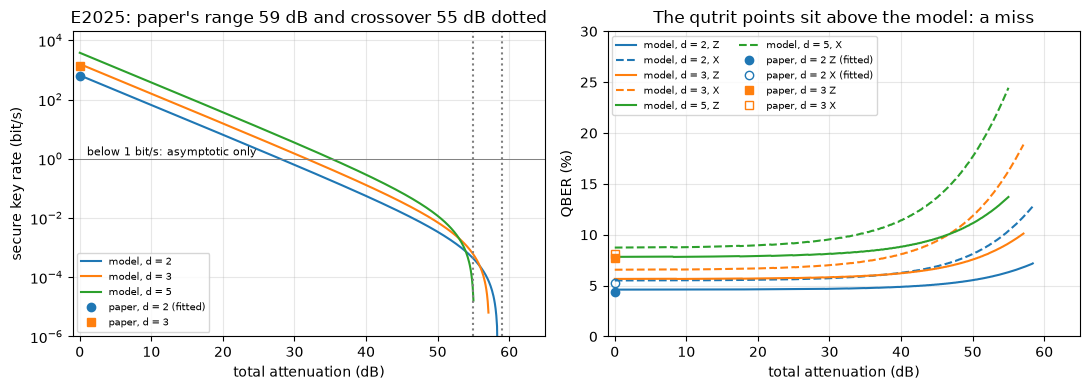

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
cols = {2: "tab:blue", 3: "tab:orange", 5: "tab:green"}
for d in (2, 3, 5):
    s = curves[d][:, 0]; w = s > 0
    a1.semilogy(alphas[w], s[w], color=cols[d], label=f"model, d = {d}")
    a2.plot(alphas[w], 100 * curves[d][w, 1], color=cols[d], label=f"model, d = {d}, Z")
    a2.plot(alphas[w], 100 * curves[d][w, 2], "--", color=cols[d], label=f"model, d = {d}, X")
a1.plot(0, 642, "o", color=cols[2], label="paper, d = 2 (fitted)"); a1.plot(0, 1374, "s", color=cols[3], label="paper, d = 3")
a1.axvline(RANGE_DB, color="gray", ls=":"); a1.axvline(CROSS_DB, color="gray", ls=":")
a1.axhline(1, color="gray", lw=0.7); a1.text(1, 1.3, "below 1 bit/s: asymptotic only", fontsize=8)
a1.set_ylim(1e-6, 2e4); a1.set_xlim(-1, 65); a1.set_xlabel("total attenuation (dB)"); a1.set_ylabel("secure key rate (bit/s)")
a1.set_title("E2025: paper's range 59 dB and crossover 55 dB dotted"); a1.legend(fontsize=7); a1.grid(alpha=0.3)
a2.plot(0, 4.4, "o", color=cols[2], label="paper, d = 2 Z (fitted)"); a2.plot(0, 5.3, "o", mfc="none", color=cols[2], label="paper, d = 2 X (fitted)")
a2.plot(0, 7.7, "s", color=cols[3], label="paper, d = 3 Z"); a2.plot(0, 8.1, "s", mfc="none", color=cols[3], label="paper, d = 3 X")
a2.set_xlim(-1, 65); a2.set_ylim(0, 30); a2.set_xlabel("total attenuation (dB)"); a2.set_ylabel("QBER (%)")
a2.set_title("The qutrit points sit above the model: a miss"); a2.legend(fontsize=7, ncol=2); a2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

**Reading the E2025 test honestly.**
- **Worked:** range and heralded g⁽²⁾. The g⁽²⁾ is the strongest test because it was not fitted, though it works only with the linewidth from Q.
- **Agreement that means less than it looks:** the qutrit key rate is about 24 % low in raw rate and 46 % high in key fraction. The crossover agrees for one rule and moves by 8 dB across rules.
- **Missed:** the qutrit QBER, about 30 % low. Errors grow with $d$ faster than a fixed $e_\text{int}$, the same pattern as the fidelity against dimension of Kues et al. 2017 in notebook 12. The optimal pump is 60 % too high because $R \propto P^2$ ignores two-photon absorption.
- **The window trend is reversed** under rule A, though the optimum is so flat that this barely matters.

## 5. E2024: a different device

E2024's two rings make bins 15 GHz apart, measured with a passive basis choice over up to 26 km. Moving E2025's $e_\text{int}$ to it is not expected to work, since $e_\text{int}$ is device-specific and the X basis here depends on the overlap of photons from two rings. Both versions are shown: **(a) strict no refit** and **(b) the device's own $e_\text{int}$ FITTED at 0 km**, then predicted along the fibre.

ASSUMED: E2024's Table III losses plus one 3.5 dB facet; the passive split is inside Table III, so these are sifted events; 700 ps full window; dark 120 Hz; $f$ = 1.2 from E2025, since E2024 gives none.

In [7]:
QBER_24 = {0.0: (0.049, 0.13), 2.6: (0.054, 0.14), 8.0: (0.057, 0.138), 10.6: (0.057, 0.14), 26.0: (0.065, 0.143)}
SPOOL_DB = {0.0: 0.0, 2.6: 1.4, 8.0: 2.0, 10.6: 3.2, 26.0: 5.0}     # measured spool losses, Bob only
R_24, TAU_24, DARK_24, Q_24, NU_24, FACET_24 = 0.7e6, 700e-12, 120.0, 1e5, 299792458.0 / 1.544e-6, 3.5
A_Z, A_X, B_Z, B_X = (8.4, 9.1), (13.0, 13.9), (16.7, 16.6), (22.5, 21.7)
G24 = NU_24 / Q_24
cap24 = 1 - np.exp(-2 * np.pi * G24 * TAU_24 / 2)
mean_dB = lambda xs: -10 * np.log10(np.mean(10 ** (-np.array(xs) / 10)))

def link24(spool):
    aZ, aX = FACET_24 + mean_dB(A_Z), FACET_24 + mean_dB(A_X)
    bZ, bX = FACET_24 + mean_dB(B_Z) + spool, FACET_24 + mean_dB(B_X) + spool
    return (sums(R_24, 10 ** (-aZ / 10), 10 ** (-bZ / 10), TAU_24, cap24, 2, DARK_24), sums(R_24, 10 ** (-aX / 10), 10 ** (-bX / 10), TAU_24, cap24, 2, DARK_24))

def e24(km, e_z, e_x, f=F_25):
    (zt, za), (xt, xa) = link24(SPOOL_DB[km])
    ez, ex = qber(zt, za, 2, e_z), qber(xt, xa, 2, e_x)
    sift = zt + za + xt + xa
    return {"e_Z": ez, "e_X": ex, "sift": sift, "SKR": max(0.0, sift * float(bracket(ez, ex, 2, f)))}

(zt0, za0), (xt0, xa0) = link24(0.0)
ez24, ex24 = QBER_24[0.0][0] - 0.5 * za0 / (zt0 + za0), QBER_24[0.0][1] - 0.5 * xa0 / (xt0 + xa0)
print(f"(b) FITTED at 0 km: e_int,Z = {ez24:.4f}, e_int,X = {ex24:.4f}\n")
print("  km    paper e_Z, e_X  | (a) E2025 e_int: e_Z, e_X | (b) own fit: e_Z, e_X, SKR")
for km, (mz, mx) in QBER_24.items():
    a_, b_ = e24(km, e_Z0, e_X0), e24(km, ez24, ex24)
    print(f" {km:5.1f}   {mz:.3f}  {mx:.3f}  |      {a_['e_Z']:.3f}  {a_['e_X']:.3f}      |  {b_['e_Z']:.3f}  {b_['e_X']:.3f}  {b_['SKR']:6.1f}")
    predict(f"strict no refit, {km} km: e_Z", a_["e_Z"], mz, "E2024 strict")
    predict(f"strict no refit, {km} km: e_X", a_["e_X"], mx, "E2024 strict")
    if km > 0:
        predict(f"own fit, {km} km: e_Z", b_["e_Z"], mz, "E2024")
        predict(f"own fit, {km} km: e_X", b_["e_X"], mx, "E2024")
r26 = e24(26.0, ez24, ex24)
predict("own fit, 26 km: SKR (bit/s), f = 1.2; paper gives a lower bound", r26["SKR"], 4.5, "E2024", "flat model QBER overshoots near threshold")
predict("own fit, 0 km: SKR (bit/s), 110 is E2025's citation of this work", e24(0.0, ez24, ex24)["SKR"], 110.0, "E2024")
car = (zt0 / 2) / (za0 / 4)
predict("CAR at 0 km, singles = pairs + dark", car, 20.0, "E2024", "the real singles carry noise photons")
x = 2 / 20
print(f"  the measured CAR ~ 20 alone gives e_Z = {x / (1 + x) / 2:.4f} vs measured 0.049, so most of this e_int is really noise photons")
mz, mx = QBER_24[26.0]
f_pos = float((1 - H_d(mx, 2)) / H_d(mz, 2))
print(f"  published 26 km QBERs at f = 1.2: bracket {float(bracket(mz, mx, 2, 1.2)):.4f}, no key. A positive key needs f < {f_pos:.3f}; E2024 states no f")
check("bracket at the published 26 km QBERs, by hand: 1 - 1.2 x 0.34696 - 0.59196", bracket(mz, mx, 2, 1.2), 1 - 1.2 * 0.34696 - 0.59196, 2e-3)
check("brightness check: 27 MHz/mW^2 x (0.4 mW after one 3.5 dB facet)^2 vs 0.7 MHz published (30 %)", 27 * (0.4 * 10 ** (-0.35)) ** 2, 0.7, 0.3, rel=True)

(b) FITTED at 0 km: e_int,Z = 0.0485, e_int,X = 0.1295

  km    paper e_Z, e_X  | (a) E2025 e_int: e_Z, e_X | (b) own fit: e_Z, e_X, SKR
   0.0   0.049  0.130  |      0.030  0.039      |  0.049  0.130    91.0
PREDICT  strict no refit, 0.0 km: e_Z: model = 0.02999, paper = 0.049, -38.8 %  [MISS]  
PREDICT  strict no refit, 0.0 km: e_X: model = 0.03898, paper = 0.13, -70.0 %  [MISS]  
   2.6   0.054  0.140  |      0.030  0.039      |  0.049  0.130    65.9
PREDICT  strict no refit, 2.6 km: e_Z: model = 0.03, paper = 0.054, -44.5 %  [MISS]  
PREDICT  strict no refit, 2.6 km: e_X: model = 0.03899, paper = 0.14, -72.2 %  [MISS]  
PREDICT  own fit, 2.6 km: e_Z: model = 0.049, paper = 0.054, -9.3 %  [agrees]  
PREDICT  own fit, 2.6 km: e_X: model = 0.13, paper = 0.14, -7.1 %  [agrees]  
   8.0   0.057  0.138  |      0.030  0.039      |  0.049  0.130    57.4
PREDICT  strict no refit, 8.0 km: e_Z: model = 0.03, paper = 0.057, -47.4 %  [MISS]  
PREDICT  strict no refit, 8.0 km: e_X: model = 0.039

## 6. BBM92: sending a real message

**Plain words:** Alice and Bob each pick a basis at random for every detected coincidence. Same basis: their bits agree, up to the QBER. Different basis: the rounds are thrown away. They reveal a random sample to estimate the QBER, correct the remaining errors with parities, and hash the result down so that what Eve could know is removed. Then the key encrypts a message as a one-time pad.

- **Cascade** (Brassard & Salvail 1993): blocks of $k_1 = \lceil 0.73/e\rceil$, doubled in each of 4 passes on fresh permutations. Each parity Alice sends counts as one leaked bit. Correcting a bit also flips the parity of its block in earlier passes, which is the cascade.
- **Toeplitz hash** (2-universal): the final length per basis string is $n[1 - H(e_\text{other basis})] - \text{leak}$ (Shor & Preskill 2000). Each string's phase error is measured by the other basis.
- **Abort rule:** abort when the estimated key length is ≤ 0, not at a fixed QBER.

N = 200,000 rounds, far more than 128 bits needs, because the biased run of section 8 still needs usable X statistics. 2000 revealed bits per basis, as in efficient BB84 (Lo, Chau & Ardehali 2005). The seed was fixed before the first run.

**Gap:** asymptotic key length, no finite-key correction; SHA-256 is the equality check, charged as 256 leaked bits per comparison; the basis is chosen per detected coincidence, so ZZ and XX are equally frequent, whereas the rate model has them about 4:1.

In [8]:
SEED, N_ROUNDS, M_SAMPLE, PASSES, TAG_BITS, MESSAGE = 24, 200_000, 2000, 4, 256, "Hello Kues group"
H2 = lambda x: float(H_d(x, 2))
e_Z, e_X = float(P0["e_Z"]), float(P0["e_X"])
Sz, Sx = zt + za, xt + xa
R_raw = (Sz + Sx) / 2
T_meas = N_ROUNDS / R_raw
print(f"model at the operating point: e_Z = {e_Z:.3f}, e_X = {e_X:.3f}; Sigma_Z = {Sz:.0f} /s, Sigma_X = {Sx:.0f} /s, R_raw = {R_raw:.0f} /s")
print(f"N = {N_ROUNDS} rounds = {T_meas:.1f} s of measurement; 128 bits alone would need about {128 / (0.5 * float(br0)):.0f} rounds")

def run_rounds(N, p_Z, e_Z, e_X, q, rng):
    """Eve intercepts Bob's photon on a fraction q of rounds in a random basis and resends. Bob's outcome is random when his basis differs
    from Alice's or from Eve's; otherwise it equals Alice's bit. The link error comes last: flipping a random outcome leaves it random."""
    a_b = rng.random(N) < p_Z
    b_b = rng.random(N) < p_Z
    a = rng.integers(0, 2, N, dtype=np.uint8)
    b = a.copy()
    eve_on = rng.random(N) < q
    eve_b = rng.random(N) < 0.5
    rand = (a_b != b_b) | (eve_on & (eve_b != b_b))
    b[rand] = rng.integers(0, 2, int(rand.sum()), dtype=np.uint8)
    b ^= (rng.random(N) < np.where(b_b, e_Z, e_X)).astype(np.uint8)
    guess = rng.integers(0, 2, N, dtype=np.uint8)
    knows = eve_on & (eve_b == a_b)
    guess[knows] = a[knows]
    return {"a_b": a_b, "b_b": b_b, "a": a, "b": b, "eve": guess, "knows": knows}

def sift(r, rng, m_Z, m_X):
    out = {}
    for name, mask, m in (("Z", r["a_b"] & r["b_b"], m_Z), ("X", ~r["a_b"] & ~r["b_b"], m_X)):
        idx = np.flatnonzero(mask)
        m = min(m, idx.size)
        perm = rng.permutation(idx.size)
        rev, keep = idx[perm[:m]], idx[perm[m:]]
        out[name] = {"n_sifted": int(idx.size), "m": int(m), "e_hat": float(np.mean(r["a"][rev] != r["b"][rev])) if m else float("nan"),
                     "a": r["a"][keep], "b": r["b"][keep], "eve": r["eve"][keep], "knows": r["knows"][keep]}
    return out

def tag(bits):
    return hashlib.sha256(np.packbits(bits).tobytes() + int(bits.size).to_bytes(8, "little")).hexdigest()

def cascade(a, b_in, e_est, rng):
    b = b_in.copy()
    n = a.size
    k1 = int(np.ceil(0.73 / max(e_est, 1e-3)))
    leak = leak_tag = 0
    passes, sizes = [], []
    def locate(p, blk):
        nonlocal leak
        members = passes[p]["blocks"][blk]
        while members.size > 1:
            half_ = members[: members.size // 2]
            leak += 1
            members = half_ if (a[half_].sum() + b[half_].sum()) % 2 else members[members.size // 2:]
        pos = int(members[0])
        b[pos] ^= 1
        for q_ in passes:
            q_["odd"] ^= {int(q_["where"][pos])}
    i = 0
    while True:
        k = min(k1 * 2 ** i, n)
        perm = np.arange(n) if i == 0 else rng.permutation(n)
        starts = np.arange(0, n, k)
        blocks = [perm[s: s + k] for s in starts]
        where = np.empty(n, dtype=np.int64)
        for bi, mem in enumerate(blocks):
            where[mem] = bi
        pa = np.add.reduceat(a[perm].astype(np.int64), starts) % 2
        pb = np.add.reduceat(b[perm].astype(np.int64), starts) % 2
        leak += starts.size
        passes.append({"blocks": blocks, "where": where, "odd": set(np.flatnonzero(pa != pb).tolist())})
        sizes.append(int(k))
        while True:
            p = next((j for j, x_ in enumerate(passes) if x_["odd"]), None)
            if p is None:
                break
            locate(p, min(passes[p]["odd"]))
        i += 1
        if i >= PASSES:
            leak_tag += TAG_BITS
            if tag(a) == tag(b) or i >= PASSES + 4:
                break
    return b, {"block_sizes": sizes, "passes": i, "leak": int(leak + leak_tag), "residual": int(np.sum(a != b)), "corrected": int(np.sum(b != b_in)), "tag_a": tag(a), "tag_b": tag(b)}

def toeplitz_hash(x, m, seed_bits):
    """y_i = sum_j T[i, j] x_j mod 2, T[i, j] = s[i - j + n - 1]. FFT, with the rounding margin checked."""
    n = x.size
    full = fftconvolve(seed_bits.astype(np.float64), x.astype(np.float64))
    assert np.max(np.abs(full - np.rint(full))) < 0.01, "FFT rounding margin lost"
    return (np.rint(full[n - 1: n - 1 + m]).astype(np.int64) % 2).astype(np.uint8)

def protocol(r, rng, m_Z, m_X, use_X_key, label):
    s = sift(r, rng, m_Z, m_X)
    ez, ex = s["Z"]["e_hat"], s["X"]["e_hat"]
    n_use = s["Z"]["a"].size + (s["X"]["a"].size if use_X_key else 0)
    est_len = n_use * float(bracket(ez, ex, 2, F_25))        # key-length rule: nothing to gain below zero
    res = {"label": label, "sift_fraction": (s["Z"]["n_sifted"] + s["X"]["n_sifted"]) / r["a"].size, "e_hat_Z": ez, "e_hat_X": ex, "n_Z": s["Z"]["n_sifted"], "n_X": s["X"]["n_sifted"], "m_Z": s["Z"]["m"], "m_X": s["X"]["m"],
           "estimated_length": est_len, "aborted": bool(est_len <= 0)}
    print(f"  [{label}] sifted fraction {res['sift_fraction']:.4f}; sample e_Z = {ez:.4f}, e_X = {ex:.4f}; estimated key length {est_len:.0f} bits; abort: {res['aborted']}")
    if res["aborted"]:
        res["final_length"] = 0
        return res, s, None, None
    A_, B_, res["strings"] = [], [], {}
    for name, e_own, e_ph in (("Z", ez, ex), ("X", ex, ez)):
        d = s[name]
        n = d["a"].size
        if n == 0 or (name == "X" and not use_X_key):
            continue
        true_e = float(np.mean(d["a"] != d["b"]))
        bob, c = cascade(d["a"], d["b"], e_own, rng)
        L_ = n * (1 - H2(e_ph)) - c["leak"]
        m = max(int(np.floor(L_)), 0)
        rec = {"n": n, "true_e": true_e, **c, "f_eff": c["leak"] / (n * H2(true_e)), "H": H2(true_e), "leak_n": c["leak"] / n, "formula": L_, "final": m}
        print(f"    {name} string: n = {n}, true error {true_e:.4f}, k = {c['block_sizes']}, passes {c['passes']}, leaked {c['leak']} bits, f_eff = {rec['f_eff']:.3f} (E2025's f = 1.2); n[1 - H({e_ph:.4f})] - leak = {L_:.1f} bits")
        if m > 0:
            sd = rng.integers(0, 2, n + m - 1, dtype=np.uint8)
            ya, yb = toeplitz_hash(d["a"], m, sd), toeplitz_hash(bob, m, sd)
            rec.update(hash_len=int(ya.size), hash_equal=bool(np.array_equal(ya, yb)), eve_agree=float(np.mean(toeplitz_hash(d["eve"], m, sd) == ya)), eve_raw=float(d["knows"].mean()))
            A_.append(ya); B_.append(yb)
        res["strings"][name] = rec
    KA = np.concatenate(A_) if A_ else np.zeros(0, dtype=np.uint8)
    KB = np.concatenate(B_) if B_ else np.zeros(0, dtype=np.uint8)
    res["final_length"], res["keys_equal"] = int(KA.size), bool(np.array_equal(KA, KB))
    return res, s, KA, KB

def otp(text, key):
    bits = np.unpackbits(np.frombuffer(text.encode("utf-8"), dtype=np.uint8))
    return np.packbits(bits ^ key[: bits.size]).tobytes()

def un_otp(cipher, key):
    bits = np.unpackbits(np.frombuffer(cipher, dtype=np.uint8))
    return np.packbits(bits ^ key[: bits.size]).tobytes()

# Tools first
rng = np.random.default_rng(SEED)
x_ = rng.integers(0, 2, 400, dtype=np.uint8)
sd_ = rng.integers(0, 2, 549, dtype=np.uint8)
direct = (toeplitz(sd_[399: 399 + 150], sd_[399::-1][:400]).astype(np.int64) @ x_.astype(np.int64) % 2).astype(np.uint8)
check("Toeplitz: FFT hash vs explicit matrix, differing bits", np.sum(toeplitz_hash(x_, 150, sd_) != direct), 0.0, 0.0)
x2 = rng.integers(0, 2, 20000, dtype=np.uint8)
sd2 = rng.integers(0, 2, 27999, dtype=np.uint8)
x3 = x2.copy(); x3[1234] ^= 1
check("Toeplitz: one input bit flipped, fraction of output bits flipped vs 1/2 (4 sigma)", np.mean(toeplitz_hash(x2, 8000, sd2) != toeplitz_hash(x3, 8000, sd2)), 0.5, 0.0224)
ta = rng.integers(0, 2, 20000, dtype=np.uint8)
tb = ta ^ (rng.random(20000) < 0.05).astype(np.uint8)
_, cc = cascade(ta, tb, 0.05, rng)
check("Cascade on a known string: remaining errors", cc["residual"], 0.0, 0.0)
check("Cascade cannot beat the Shannon limit: leak/n above H(e) (1 = yes)", cc["leak"] / 20000 > H2(float(np.mean(ta != tb))), 1.0, 0.0)

print("\nhonest run, p_Z = 0.5")
rng = np.random.default_rng(SEED + 1)
r = run_rounds(N_ROUNDS, 0.5, e_Z, e_X, 0.0, rng)
res, s, KA, KB = protocol(r, rng, M_SAMPLE, M_SAMPLE, True, "p_Z = 0.5, no Eve")
mism = r["a_b"] != r["b_b"]
check_sigma("sifting fraction", res["sift_fraction"], 0.5, N_ROUNDS)
check_sigma("different-basis rounds agree at random", float(np.mean(r["a"][mism] == r["b"][mism])), 0.5, int(mism.sum()))
check_sigma("sample QBER Z", res["e_hat_Z"], e_Z, res["m_Z"])
check_sigma("sample QBER X", res["e_hat_X"], e_X, res["m_X"])
for name, e_ in (("Z", e_Z), ("X", e_X)):
    st_ = res["strings"][name]
    check_sigma(f"{name} string: true error rate", st_["true_e"], e_, st_["n"])
    check(f"{name} string: positions corrected vs errors counted directly", st_["corrected"], st_["true_e"] * st_["n"], 0.5)
    check(f"{name} string: remaining errors after Cascade", st_["residual"], 0.0, 0.0)
    check(f"{name} string: SHA-256 of Alice's and Bob's strings match (1 = yes)", st_["tag_a"] == st_["tag_b"], 1.0, 0.0)
    check(f"{name} string: leak/n above the Shannon limit (1 = yes)", st_["leak_n"] > st_["H"], 1.0, 0.0)
    check(f"{name} string: hash output length vs floor(n[1 - H] - leak)", st_["hash_len"], np.floor(st_["formula"]), 0.0)
    check(f"{name} string: hash outputs equal (1 = yes)", st_["hash_equal"], 1.0, 0.0)
check("final keys identical (1 = yes)", res["keys_equal"], 1.0, 0.0)
n_key = res["strings"]["Z"]["n"] + res["strings"]["X"]["n"]
print(f"final key {res['final_length']} bits in {T_meas:.1f} s = {res['final_length'] / T_meas:.0f} bit/s; the model's {float(P0['SKR']):.0f} bit/s after removing the revealed sample gives {float(P0['SKR']) * n_key / (res['n_Z'] + res['n_X']):.0f} bit/s")
check("key rate vs model after the sample (relative, 8 %: about 2 sigma of the two samples)", res["final_length"] / T_meas, float(P0["SKR"]) * n_key / (res["n_Z"] + res["n_X"]), 0.08, rel=True)
ct = otp(MESSAGE, KA)
decrypted = un_otp(ct, KB).decode("utf-8", errors="replace")
print(f"\n  plaintext:  {MESSAGE}\n  ciphertext: {ct.hex()}\n  decrypted:  {decrypted}\n")
check("message length in bits vs 128", 8 * len(MESSAGE.encode("utf-8")), 128.0, 0.0)
check("decrypted text equals the original (1 = yes)", decrypted == MESSAGE, 1.0, 0.0)
check("negative control: Bob's raw bits do not decrypt it (1 = correct)", un_otp(ct, s["Z"]["b"][:128]) != MESSAGE.encode("utf-8"), 1.0, 0.0)

model at the operating point: e_Z = 0.044, e_X = 0.053; Sigma_Z = 5282 /s, Sigma_X = 1327 /s, R_raw = 3304 /s
N = 200000 rounds = 60.5 s of measurement; 128 bits alone would need about 659 rounds
PASS  Toeplitz: FFT hash vs explicit matrix, differing bits: model = 0, check = 0
PASS  Toeplitz: one input bit flipped, fraction of output bits flipped vs 1/2 (4 sigma): model = 0.503125, check = 0.5
PASS  Cascade on a known string: remaining errors: model = 0, check = 0
PASS  Cascade cannot beat the Shannon limit: leak/n above H(e) (1 = yes): model = 1, check = 1

honest run, p_Z = 0.5
  [p_Z = 0.5, no Eve] sifted fraction 0.4979; sample e_Z = 0.0520, e_X = 0.0440; estimated key length 36882 bits; abort: False
    Z string: n = 47867, true error 0.0443, k = [15, 30, 60, 120], passes 4, leaked 15012 bits, f_eff = 1.199 (E2025's f = 1.2); n[1 - H(0.0440)] - leak = 20393.3 bits
    X string: n = 47716, true error 0.0523, k = [17, 34, 68, 136], passes 4, leaked 16465 bits, f_eff = 1.165 (E2025's

PASS  sifting fraction: MC = 0.49791, model = 0.50000, off by -1.86 sigma (n = 200000)


PASS  different-basis rounds agree at random: MC = 0.49905, model = 0.50000, off by -0.60 sigma (n = 100417)
PASS  sample QBER Z: MC = 0.05200, model = 0.04400, off by +1.74 sigma (n = 2000)
PASS  sample QBER X: MC = 0.04400, model = 0.05300, off by -1.80 sigma (n = 2000)
PASS  Z string: true error rate: MC = 0.04429, model = 0.04400, off by +0.31 sigma (n = 47867)
PASS  Z string: positions corrected vs errors counted directly: model = 2120, check = 2120
PASS  Z string: remaining errors after Cascade: model = 0, check = 0
PASS  Z string: SHA-256 of Alice's and Bob's strings match (1 = yes): model = 1, check = 1
PASS  Z string: leak/n above the Shannon limit (1 = yes): model = 1, check = 1
PASS  Z string: hash output length vs floor(n[1 - H] - leak): model = 20393, check = 20393
PASS  Z string: hash outputs equal (1 = yes): model = 1, check = 1
PASS  X string: true error rate: MC = 0.05233, model = 0.05300, off by -0.65 sigma (n = 47716)
PASS  X string: positions corrected vs errors co

## 7. Intercept-resend Eve

**Plain words:** Eve measures Bob's photon in a random basis and sends on what she saw. When she picks the wrong basis, Bob's outcome becomes random, half the time wrong. So a fraction $q$ of attacked rounds adds **about $q/4$** to the QBER.

The precise form is $e + (q/4)(1 - 2e)$, not $e + q/4$, since a random outcome cannot get more random. QuTiP confirms it on the state below.

**A correction that matters:** a fixed 11 % abort threshold is the wrong test. With $f$ = 1.2 the key reaches zero at q = 0.21, but the 11 % threshold fires only at q = 0.255. Between the two, the protocol would run and produce no key. So the abort rule used here is the estimated key length.

PASS  QuTiP, e = 0.044, q = 0.2: Z QBER of the state vs e + (q/4)(1 - 2e): model = 0.0896, check = 0.0896
PASS  QuTiP, e = 0.044, q = 0.2: X QBER of the state vs e + (q/4)(1 - 2e): model = 0.0896, check = 0.0896
PASS  QuTiP, e = 0.044, q = 1.0: Z QBER of the state vs e + (q/4)(1 - 2e): model = 0.272, check = 0.272
PASS  QuTiP, e = 0.044, q = 1.0: X QBER of the state vs e + (q/4)(1 - 2e): model = 0.272, check = 0.272
PASS  QuTiP, e = 0.053, q = 0.2: Z QBER of the state vs e + (q/4)(1 - 2e): model = 0.0977, check = 0.0977
PASS  QuTiP, e = 0.053, q = 0.2: X QBER of the state vs e + (q/4)(1 - 2e): model = 0.0977, check = 0.0977
PASS  QuTiP, e = 0.053, q = 1.0: Z QBER of the state vs e + (q/4)(1 - 2e): model = 0.2765, check = 0.2765
PASS  QuTiP, e = 0.053, q = 1.0: X QBER of the state vs e + (q/4)(1 - 2e): model = 0.2765, check = 0.2765
  [q = 1.0] sifted fraction 0.4973; sample e_Z = 0.2855, e_X = 0.2730; estimated key length -84120 bits; abort: True
PASS  q = 1.0: sample QBER Z: MC = 0.28

    X string: n = 48109, true error 0.0984, k = [8, 16, 32, 64], passes 4, leaked 26870 bits, f_eff = 1.204 (E2025's f = 1.2); n[1 - H(0.0850)] - leak = 1054.6 bits
PASS  q = 0.2: sample QBER Z: MC = 0.08500, model = 0.08960, off by -0.72 sigma (n = 2000)
PASS  q = 0.2: sample QBER X: MC = 0.10200, model = 0.09770, off by +0.65 sigma (n = 2000)
  q = 0.2: rise measured Z +0.0410, X +0.0490; q/4 = 0.0500
  q = 0.2: final key 1054 bits, 2.8 % of the honest key; asymptotic bracket 0.0162 against 0.3886
  q = 0.2: one sigma of the samples moves the key fraction by 0.030, more than the bracket itself, so whether a key survives here is decided by the sample: marginal
  q = 0.2, X string: Eve knew 10.1 % of the raw bits, agreement with the amplified key 0.5085
PASS  q = 0.2, X string: Eve's agreement with the amplified key vs 1/2 (4 sigma): model = 0.508539, check = 0.5
PASS  q = 0.2: the shorter key still carries the message (1 = yes): model = 1, check = 1

from the formula: key reaches zero

sweep of 42 points: 100 % inside 2 sigma (about 95 % expected), largest 1.91 sigma
PASS  sweep: largest deviation below 3.5 sigma (1 = yes): model = 1, check = 1
PASS  QBER slope vs q on all sifted bits, Z, vs (1 - 2e)/4 (additive model has 0.25): model = 0.228328, check = 0.228
PASS  QBER slope vs q on all sifted bits, X, vs (1 - 2e)/4: model = 0.221801, check = 0.2235


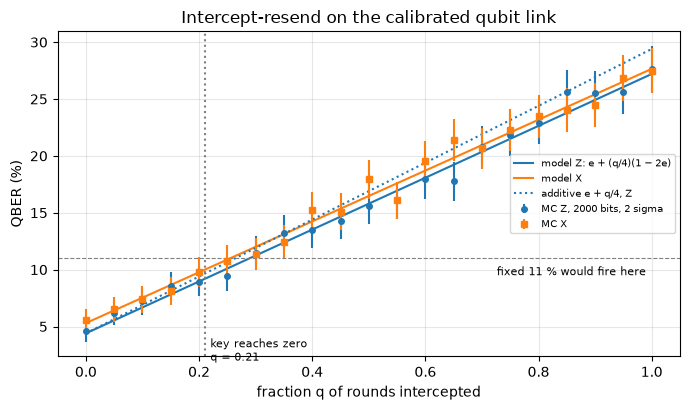

In [9]:
bell = (qt.tensor(qt.basis(2, 0), qt.basis(2, 0)) + qt.tensor(qt.basis(2, 1), qt.basis(2, 1))).unit()
plus, minus = (qt.basis(2, 0) + qt.basis(2, 1)).unit(), (qt.basis(2, 0) - qt.basis(2, 1)).unit()
Zb, Xb = [qt.basis(2, 0), qt.basis(2, 1)], [plus, minus]

def eve_channel(rho, q):
    o = (1 - q) * rho
    for basis in (Zb, Xb):
        for st_ in basis:
            Pb = qt.tensor(qt.qeye(2), st_ * st_.dag())
            o = o + (q / 2) * Pb * rho * Pb
    return o

def qber_state(rho, basis):
    err = tot = 0.0
    for i, sa_ in enumerate(basis):
        for j, sb_ in enumerate(basis):
            v = qt.tensor(sa_, sb_)
            pr = float(np.real(v.dag() * rho * v))
            tot += pr
            err += pr if i != j else 0.0
    return err / tot

for e_ in (e_Z, e_X):
    rho0 = (1 - 2 * e_) * bell * bell.dag() + 2 * e_ * qt.tensor(qt.qeye(2), qt.qeye(2)) / 4
    for q_ in (0.2, 1.0):
        rho = eve_channel(rho0, q_)
        exact = e_ + q_ / 4 * (1 - 2 * e_)
        check(f"QuTiP, e = {e_:.3f}, q = {q_}: Z QBER of the state vs e + (q/4)(1 - 2e)", qber_state(rho, Zb), exact, 1e-9)
        check(f"QuTiP, e = {e_:.3f}, q = {q_}: X QBER of the state vs e + (q/4)(1 - 2e)", qber_state(rho, Xb), exact, 1e-9)

for q in (1.0, 0.2):
    rng = np.random.default_rng(SEED + int(1000 * q) + 2)
    re_ = run_rounds(N_ROUNDS, 0.5, e_Z, e_X, q, rng)
    ri, si, KAe, KBe = protocol(re_, rng, M_SAMPLE, M_SAMPLE, True, f"q = {q}")
    mz, mx = e_Z + q / 4 * (1 - 2 * e_Z), e_X + q / 4 * (1 - 2 * e_X)
    check_sigma(f"q = {q}: sample QBER Z", ri["e_hat_Z"], mz, ri["m_Z"])
    check_sigma(f"q = {q}: sample QBER X", ri["e_hat_X"], mx, ri["m_X"])
    print(f"  q = {q}: rise measured Z {ri['e_hat_Z'] - e_Z:+.4f}, X {ri['e_hat_X'] - e_X:+.4f}; q/4 = {q / 4:.4f}")
    if ri["aborted"]:
        print(f"  q = {q}: the estimated key length is negative, so the protocol aborts: no key, no message")
        check(f"q = {q}: protocol aborts (1 = yes)", ri["aborted"], 1.0, 0.0)
    else:
        print(f"  q = {q}: final key {ri['final_length']} bits, {ri['final_length'] / res['final_length'] * 100:.1f} % of the honest key; asymptotic bracket {float(bracket(mz, mx, 2, F_25)):.4f} against {float(br0):.4f}")
        sens_ = np.hypot(np.log2((1 - mx) / mx) * np.sqrt(mx * (1 - mx) / M_SAMPLE), np.log2((1 - mz) / mz) * np.sqrt(mz * (1 - mz) / M_SAMPLE))
        print(f"  q = {q}: one sigma of the samples moves the key fraction by {sens_:.3f}, more than the bracket itself, so whether a key survives here is decided by the sample: marginal")
        for name, st_ in ri["strings"].items():
            if st_["final"] > 0:
                print(f"  q = {q}, {name} string: Eve knew {st_['eve_raw'] * 100:.1f} % of the raw bits, agreement with the amplified key {st_['eve_agree']:.4f}")
                check(f"q = {q}, {name} string: Eve's agreement with the amplified key vs 1/2 (4 sigma)", st_["eve_agree"], 0.5, 4 * 0.5 / np.sqrt(st_["final"]))
        if ri["final_length"] >= 128:
            check(f"q = {q}: the shorter key still carries the message (1 = yes)", un_otp(otp(MESSAGE, KAe), KBe).decode("utf-8", errors="replace") == MESSAGE, 1.0, 0.0)

q_11 = min((0.11 - e_) / (0.25 * (1 - 2 * e_)) for e_ in (e_Z, e_X))
q_zero = brentq(lambda q: float(bracket(e_Z + q / 4 * (1 - 2 * e_Z), e_X + q / 4 * (1 - 2 * e_X), 2, F_25)), 0.0, 1.0)
print(f"\nfrom the formula: key reaches zero at q = {q_zero:.3f} (f = 1.2); a fixed 11 % threshold would fire only at q = {q_11:.3f}")
check("key reaches zero before the 11 % threshold fires (1 = yes)", q_zero < q_11, 1.0, 0.0)

Q_ = np.round(np.arange(0.0, 1.0001, 0.05), 2)
sw = []
for i, q in enumerate(Q_):
    rng = np.random.default_rng(SEED + 100 + i)
    re_ = run_rounds(N_ROUNDS, 0.5, e_Z, e_X, float(q), rng)
    si = sift(re_, rng, M_SAMPLE, M_SAMPLE)
    zm, xm = re_["a_b"] & re_["b_b"], ~re_["a_b"] & ~re_["b_b"]
    sw.append((si["Z"]["e_hat"], si["X"]["e_hat"], float(np.mean(re_["a"][zm] != re_["b"][zm])), float(np.mean(re_["a"][xm] != re_["b"][xm]))))
sw = np.array(sw)
mzs, mxs = e_Z + Q_ / 4 * (1 - 2 * e_Z), e_X + Q_ / 4 * (1 - 2 * e_X)
devs = np.concatenate((np.abs(sw[:, 0] - mzs) / np.sqrt(mzs * (1 - mzs) / M_SAMPLE), np.abs(sw[:, 1] - mxs) / np.sqrt(mxs * (1 - mxs) / M_SAMPLE)))
print(f"sweep of 42 points: {np.mean(devs <= 2) * 100:.0f} % inside 2 sigma (about 95 % expected), largest {devs.max():.2f} sigma")
check("sweep: largest deviation below 3.5 sigma (1 = yes)", devs.max() <= 3.5, 1.0, 0.0)
check("QBER slope vs q on all sifted bits, Z, vs (1 - 2e)/4 (additive model has 0.25)", np.polyfit(Q_, sw[:, 2], 1)[0], (1 - 2 * e_Z) / 4, 0.003)
check("QBER slope vs q on all sifted bits, X, vs (1 - 2e)/4", np.polyfit(Q_, sw[:, 3], 1)[0], (1 - 2 * e_X) / 4, 0.003)

fig, ax = plt.subplots(figsize=(7, 4.2))
qq = np.linspace(0, 1, 101)
ax.plot(qq, 100 * (e_Z + qq / 4 * (1 - 2 * e_Z)), color="tab:blue", label="model Z: e + (q/4)(1 − 2e)")
ax.plot(qq, 100 * (e_X + qq / 4 * (1 - 2 * e_X)), color="tab:orange", label="model X")
ax.plot(qq, 100 * (e_Z + qq / 4), ":", color="tab:blue", label="additive e + q/4, Z")
ax.errorbar(Q_, 100 * sw[:, 0], yerr=200 * np.sqrt(sw[:, 0] * (1 - sw[:, 0]) / M_SAMPLE), fmt="o", ms=4, color="tab:blue", label="MC Z, 2000 bits, 2 sigma")
ax.errorbar(Q_, 100 * sw[:, 1], yerr=200 * np.sqrt(sw[:, 1] * (1 - sw[:, 1]) / M_SAMPLE), fmt="s", ms=4, color="tab:orange", label="MC X")
ax.axvline(q_zero, color="gray", ls=":"); ax.text(q_zero + 0.01, 2, f"key reaches zero\nq = {q_zero:.2f}", fontsize=8)
ax.axhline(11, color="gray", ls="--", lw=0.8); ax.text(0.99, 10.3, "fixed 11 % would fire here", fontsize=8, ha="right", va="top")
ax.set_xlabel("fraction q of rounds intercepted"); ax.set_ylabel("QBER (%)"); ax.set_title("Intercept-resend on the calibrated qubit link")
ax.legend(fontsize=7); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

## 8. Biased bases

**Plain words:** if both users pick Z most of the time, fewer rounds are thrown away: the sifted fraction is $p_Z^2 + p_X^2$. X is then only a spot check that bounds what Eve knows (efficient BB84). The cost is a smaller X sample. With the seed fixed before the run, the X sample below comes out 2.17 σ high and shortens the key, so 30 other seeds are shown beside it. That excursion would fail a 2 σ test and passes the 3 σ test used here; 1000 other seeds show it is chance.

In [10]:
pz_ = 0.9
rng = np.random.default_rng(SEED + 7)
rb = run_rounds(N_ROUNDS, pz_, e_Z, e_X, 0.0, rng)
n_XX = int(np.sum(~rb["a_b"] & ~rb["b_b"]))
res_b, sb, KA2, KB2 = protocol(rb, rng, M_SAMPLE, n_XX, False, "p_Z = 0.9, no Eve")
check_sigma("sifting fraction", res_b["sift_fraction"], pz_ ** 2 + (1 - pz_) ** 2, N_ROUNDS)
check_sigma("XX fraction", res_b["n_X"] / N_ROUNDS, (1 - pz_) ** 2, N_ROUNDS)
check_sigma("sample QBER Z", res_b["e_hat_Z"], e_Z, res_b["m_Z"])
check_sigma("sample QBER X", res_b["e_hat_X"], e_X, res_b["m_X"])
st_ = res_b["strings"]["Z"]
check("Z string: remaining errors after Cascade", st_["residual"], 0.0, 0.0)
check("Z string: hash output length vs floor(n[1 - H(e_X)] - leak)", st_["hash_len"], np.floor(st_["formula"]), 0.0)
check("decrypted text with the biased key (1 = correct)", un_otp(otp(MESSAGE, KA2), KB2).decode("utf-8", errors="replace") == MESSAGE, 1.0, 0.0)
print(f"50/50: sifted {res['sift_fraction']:.3f}, final {res['final_length']} bits. p_Z = 0.9: sifted {res_b['sift_fraction']:.3f}, final {res_b['final_length']} bits. This seed: key x {res_b['final_length'] / res['final_length']:.2f}, sifted x {res_b['sift_fraction'] / res['sift_fraction']:.3f} (formula 1.64)")
xh, nh = [], []
for i in range(1000):
    rd = np.random.default_rng(SEED + 10000 + i)
    rx_ = run_rounds(N_ROUNDS, pz_, e_Z, e_X, 0.0, rd)
    mask = ~rx_["a_b"] & ~rx_["b_b"]
    xh.append(float(np.mean(rx_["a"][mask] != rx_["b"][mask]))); nh.append(int(mask.sum()))
xh, nh = np.array(xh), np.array(nh)
print(f"1000 other seeds, XX sample: mean {xh.mean():.5f} (model {e_X:.5f}), inside 2 sigma {np.mean(np.abs(xh - e_X) <= 2 * np.sqrt(e_X * (1 - e_X) / nh)) * 100:.1f} %, reaching +2.17 sigma {np.mean((xh - e_X) / np.sqrt(e_X * (1 - e_X) / nh) >= 2.17) * 100:.1f} %")
check("1000 seeds: mean XX sample QBER vs model (4 standard errors)", xh.mean(), e_X, 4 * np.sqrt(e_X * (1 - e_X) / nh.mean() / 1000))
ratios = []
for i in range(30):
    rd = np.random.default_rng(SEED + 20000 + i)
    with contextlib.redirect_stdout(io.StringIO()):
        ru = protocol(run_rounds(N_ROUNDS, 0.5, e_Z, e_X, 0.0, rd), rd, M_SAMPLE, M_SAMPLE, True, "other seed")[0]
        rt = run_rounds(N_ROUNDS, pz_, e_Z, e_X, 0.0, rd)
        rb2 = protocol(rt, rd, M_SAMPLE, int(np.sum(~rt["a_b"] & ~rt["b_b"])), False, "other seed")[0]
    ratios.append(rb2["final_length"] / ru["final_length"])
print(f"30 other seeds: key gain {np.mean(ratios):.2f} +- {np.std(ratios, ddof=1):.2f} over 50/50")
check("mean key gain over 30 seeds vs sifting gain 1.64 (3 standard errors + 2 % for the smaller sample share)", np.mean(ratios), 1.64, 3 * np.std(ratios, ddof=1) / np.sqrt(30) + 0.033)
print(f"in time rather than per coincidence: with Sigma_Z / Sigma_X = {Sz / Sx:.2f}, the sifted rate gains x {(pz_ ** 2 * Sz + (1 - pz_) ** 2 * Sx) / (0.25 * Sz + 0.25 * Sx):.2f}")

  [p_Z = 0.9, no Eve] sifted fraction 0.8204; sample e_Z = 0.0415, e_X = 0.0638; estimated key length 57397 bits; abort: False


    Z string: n = 160067, true error 0.0436, k = [18, 36, 72, 144], passes 4, leaked 48097 bits, f_eff = 1.163 (E2025's f = 1.2); n[1 - H(0.0638)] - leak = 57152.9 bits
PASS  sifting fraction: MC = 0.82044, model = 0.82000, off by +0.51 sigma (n = 200000)
PASS  XX fraction: MC = 0.01010, model = 0.01000, off by +0.47 sigma (n = 200000)
PASS  sample QBER Z: MC = 0.04150, model = 0.04400, off by -0.55 sigma (n = 2000)
PASS  sample QBER X: MC = 0.06383, model = 0.05300, off by +2.17 sigma (n = 2021)
PASS  Z string: remaining errors after Cascade: model = 0, check = 0
PASS  Z string: hash output length vs floor(n[1 - H(e_X)] - leak): model = 57152, check = 57152
PASS  decrypted text with the biased key (1 = correct): model = 1, check = 1
50/50: sifted 0.498, final 37575 bits. p_Z = 0.9: sifted 0.820, final 57152 bits. This seed: key x 1.52, sifted x 1.648 (formula 1.64)


1000 other seeds, XX sample: mean 0.05275 (model 0.05300), inside 2 sigma 94.7 %, reaching +2.17 sigma 2.1 %
PASS  1000 seeds: mean XX sample QBER vs model (4 standard errors): model = 0.0527534, check = 0.053


30 other seeds: key gain 1.69 +- 0.12 over 50/50
PASS  mean key gain over 30 seeds vs sifting gain 1.64 (3 standard errors + 2 % for the smaller sample share): model = 1.69342, check = 1.64
in time rather than per coincidence: with Sigma_Z / Sigma_X = 3.98, the sifted rate gains x 2.60


## 9. From ring design to key rate: the machinery

**Plain words:** the same rate model, with the device and the receiver as blocks that can be swapped.

**Decisions, stated:**
- **Pump:** held at the paper's optimum (3.9 mW for $d = 2$, 3.5 mW for $d = 3, 5$), never above, lowered only where that raises the key. No two-photon-absorption term is added.
- **$e_\text{int}$ for $d > 2$:** rule B is central. Rule A is optimistic. Rule C is pessimistic and was chosen after seeing the data, so it is labelled.
- **Q → photon length, two ways:** *peak* uses the published Voigt with the Lorentzian part $\propto 1/G$, so Q 4.75 × 10⁵ gives the measured 410 ps; *Q* uses the ring's own $e^{-2\pi G|t|}$ convolved with the same detector Gaussian. Each model is refitted at Q 4.75 × 10⁵.
- **Absolute rates** come only from the fit above. The ring cards give **ratios** (QKD ring / Kues ring): their own absolute rates are not used, see notebook 16. ASSUMED anchor: the Kues ring is driven to the fitted pair rate.
- **Bin brightness** is the overlap rule $1/(1 + (\Delta_k/G)^2)$ (notebook 13).

$$\text{SKR} = \bigl(p_Z^2\,\Sigma_Z + p_X^2\,\Sigma_X/x_\text{div}\bigr)\,\bigl[\log_2 d - f H_d(e_Z) - H_d(e_X)\bigr]$$

At $p_Z = 1/2$, $x_\text{div} = 1$ this is E2025's formula. Z and X never act on the same photon: they occupy time fractions $p_Z^2$ and $p_X^2$, and the mismatched $2p_Zp_X$ is discarded.

In [11]:
KM, G0, C_LIGHT = 0.2, NU_25 / Q_25, 299792458.0
P_CAP = {2: 3.9, 3: 3.5, 5: 3.5}
MU_FREE = 0.1                    # ASSUMED, free-pump case for the glass ring only: (P/P_th)^2 <= 0.1
B_SIDE = 80 * FSR_25             # E2025's 80 modes per side = 1.70 THz, ASSUMED fixed as FSR changes
F_RF_MAX = 40e9                  # ASSUMED highest RF tone; above it the FSR is bridged by sideband order m (Kues 2017 Methods)
N_X_MIN, T_BLOCK = 1000, 3600.0  # ASSUMED: 1000 X events per hour block sets how far p_Z can go. Not a finite-key proof
PX_MIN, M_REF, R3_L = 0.05, 0.921, 3.0
DT = np.geomspace(30e-12, 30e-9, 140)
R_SCALE = np.geomspace(1e-7, 1.0, 57)
Dd = (2, 3, 5)

_T = np.concatenate(([0.0], np.geomspace(1e-13, 3e-7, 8000)))
_pdf, _cap = {}, {}
def peak_pdf(model, G):
    key = (model, round(G, 3))
    if key not in _pdf:
        if model == "peak":
            _pdf[key] = voigt_profile(_T, V_SIGMA, V_GAMMA * G0 / G)
        else:
            Gam, s_ = 2 * np.pi * G, V_SIGMA
            u, v = (Gam * s_ ** 2 - _T) / (np.sqrt(2) * s_), (Gam * s_ ** 2 + _T) / (np.sqrt(2) * s_)
            _pdf[key] = Gam / 4 * (np.exp(Gam ** 2 * s_ ** 2 / 2 - Gam * _T) * erfc(u) + np.exp(-_T ** 2 / (2 * s_ ** 2)) * erfcx(v))
    return _pdf[key]
def cap_at(model, G, dt):
    key = (model, round(G, 3))
    if key not in _cap:
        p_ = peak_pdf(model, G)
        _cap[key] = 2 * np.concatenate(([0.0], np.cumsum((p_[1:] + p_[:-1]) / 2 * np.diff(_T))))
    return np.interp(dt, _T, _cap[key])
def fwhm(model, G):
    p_ = peak_pdf(model, G)
    return 2 * np.interp(0.5, p_[::-1] / p_[0], _T[::-1])

@dataclass
class Cal:
    model: str; R: float; e_Z: float; e_X: float; q_Z: float; q_X: float
    def intr(self, rule): return Intrinsic(rule, self.e_Z, self.e_X, self.q_Z, self.q_X)
    def e_int(self, rule, d, basis):
        e = self.e_Z if basis == "Z" else self.e_X
        return e if rule == "A" else (d - 1) / d * 2 * e

def calibrate(model):
    c = cap_at(model, G0, q2["dt"])
    def rates(R):
        eX = ETA0 * 10 ** (-LOSS_X_25 / 10)
        return sums(R, ETA0, ETA0, 2 * q2["dt"], c, 2, DARK_25), sums(R, eX, eX, 2 * q2["dt"], c, 2, DARK_25)
    def res_(x):
        R, ez, ex = np.exp(x[0]), x[1], x[2]
        (zt_, za_), (xt_, xa_) = rates(R)
        Ez, Ex = qber(zt_, za_, 2, ez), qber(xt_, xa_, 2, ex)
        return [np.log(0.25 * (zt_ + za_ + xt_ + xa_) * bracket(Ez, Ex, 2, F_25) / q2["SKR_max"]), Ez - q2["e_Z"], Ex - q2["e_X"]]
    s_ = fsolve(res_, [np.log(1e7), 0.03, 0.03], xtol=1e-12)
    R = float(np.exp(s_[0]))
    (zt_, za_), (xt_, xa_) = rates(R)
    return Cal(model, R, float(s_[1]), float(s_[2]), float((y_Z - za_ / zt_) / 2), float((y_X - xa_ / xt_) / 2))

def x_eom_dB(d, mu=1.2):
    """Single-tone modulator of index mu: a bin k channels away reaches the common channel with amplitude J_k(mu) (Jacobi-Anger). The uniform projector
    needs equal weights, so the filter attenuates every bin to the weakest one, w = min |J_k|, and a uniform superposition leaves with P = d w^2."""
    offs = {2: (-1, 1), 3: (-1, 0, 1), 5: (-2, -1, 0, 1, 2)}[d]
    return -10 * np.log10(d * min(abs(jv(k, mu)) for k in offs) ** 2)
x_ddep = lambda d: LOSS_X_25 + x_eom_dB(d) - x_eom_dB(2)     # d = 2 stays at the fitted 3 dB, so no refit

def sideband_penalty(fsr):
    m = int(np.ceil(fsr / F_RF_MAX - 1e-9))
    return (0.0, 1) if m <= 1 else (float(10 * np.log10(jv(1, 1.2) ** 2 / jv(m, jnp_zeros(m, 1)[0]) ** 2)), m)

@dataclass
class Device:
    label: str; cal: Cal; G: float; eta_rel: float; Rmax: Callable[[int], float]; x_pen: float = 0.0

@dataclass
class Rx:
    name: str; p_Z: float = 0.5; floor: bool = False; hardware: bool = False; x_L: Optional[float] = None; xmode: str = "flat"; e_X_val: Optional[float] = None; e_Z_val: Optional[float] = None

def evaluate(dev, rx, d, rule, alpha, R, dt=DT, e_add=0.0):
    R_ = np.atleast_1d(R)[:, None]
    dt_ = np.atleast_1d(dt)[None, :]
    c = cap_at(dev.cal.model, dev.G, dt_)
    tau = 2 * dt_
    x = (rx.x_L if rx.x_L is not None else (x_ddep(d) if rx.xmode == "ddep" else LOSS_X_25)) + dev.x_pen
    eZ = ETA0 * dev.eta_rel * 10 ** (-alpha / 20)
    eX = eZ * 10 ** (-x / 10)
    zt_, za_ = sums(R_, eZ, eZ, tau, c, d, DARK_25)
    xt_, xa_ = sums(R_, eX, eX, tau, c, d, DARK_25)
    I = dev.cal.intr(rule)
    ez = qber(zt_, za_, d, rx.e_Z_val) if rx.e_Z_val is not None else I.apply(zt_, za_, d, "Z")
    if rx.e_X_val is not None:
        ex = qber(xt_, xa_, d, max(rx.e_X_val + e_add, 0.0))
    elif rule in ("A", "B"):
        ex = qber(xt_, xa_, d, max(dev.cal.e_int(rule, d, "X") + e_add, 0.0))
    else:
        ex = np.maximum(I.apply(xt_, xa_, d, "X") + e_add, (d - 1) / d * xa_ / (xt_ + xa_))
    SZ, SX = zt_ + za_, xt_ + xa_
    div = d ** 2 if rx.hardware else 1
    p_X = np.clip(np.sqrt(N_X_MIN / (T_BLOCK * SX / div)), PX_MIN, 0.5) if rx.floor else (1 - rx.p_Z) * np.ones_like(SZ)
    p_Z = 1 - p_X
    b_ = bracket(ez, ex, d, F_25)
    lim = (d - 1) / d
    b_ = np.where((ez >= lim) | (ex >= lim), 0.0, b_)
    return {"SKR": (p_Z ** 2 * SZ + p_X ** 2 * SX / div) * np.maximum(b_, 0.0), "e_Z": ez, "e_X": ex, "p_Z": p_Z, "N_X_h": p_X ** 2 * SX / div * T_BLOCK, "SZ": SZ, "SX": SX}

def best(dev, rx, d, rule, alpha, policy="held", e_add=0.0):
    R = {"held": dev.Rmax(d) * R_SCALE, "fixed": np.array([dev.Rmax(d)]), "free": MU_FREE * (2 * np.pi * dev.G) / 2 * R_SCALE}[policy]
    o = evaluate(dev, rx, d, rule, alpha, R, e_add=e_add)
    i = np.unravel_index(int(np.argmax(o["SKR"])), o["SKR"].shape)
    return {"SKR": float(o["SKR"][i]), "dt": float(DT[i[1]]), "R": float(R[i[0]]), "e_Z": float(o["e_Z"][i]), "e_X": float(o["e_X"][i]), "p_Z": float(o["p_Z"][i]), "N_X_h": float(o["N_X_h"][i])}

def reach(dev, rx, d, rule, level, policy="held", e_add=0.0):
    f = lambda a: best(dev, rx, d, rule, a, policy, e_add)["SKR"] > level
    if not f(0.0):
        return 0.0
    lo_, hi_ = 0.0, 130.0
    for _ in range(14):
        mid = (lo_ + hi_) / 2
        lo_, hi_ = (mid, hi_) if f(mid) else (lo_, mid)
    return lo_

def report(dev, rx, d, rule, policy="held", e_add=0.0):
    a_max, a_1 = reach(dev, rx, d, rule, 0.0, policy, e_add), reach(dev, rx, d, rule, 1.0, policy, e_add)
    at_r = best(dev, rx, d, rule, max(a_max - 0.02, 0.0), policy, e_add)["SKR"]
    return {"S0": best(dev, rx, d, rule, 0.0, policy, e_add)["SKR"], "S25": best(dev, rx, d, rule, 25 * KM, policy, e_add)["SKR"], "S150": best(dev, rx, d, rule, 150 * KM, policy, e_add)["SKR"],
            "range_km": a_max / KM, "S_range": at_r, "reach_km": a_1 / KM}

asym = lambda v: " [asymptotic only]" if 0 < v < 1 else ""
def row_txt(r_):
    if r_["range_km"] <= 0:
        return "no key at any distance"
    return (f"SKR 0/25/150 km = {r_['S0']:.3g} / {r_['S25']:.3g} / {r_['S150']:.3g}{asym(r_['S150'])} bit/s; 1 bit/s reach {r_['reach_km']:.0f} km; "
            f"range {r_['range_km']:.0f} km at {r_['S_range']:.0e} bit/s [asymptotic only]")

cal = {m: calibrate(m) for m in ("peak", "Q")}
check("peak model: refit R vs section 3 (relative)", cal["peak"].R, R_cal, 1e-5, rel=True)
check("peak model: FWHM at Q 4.75e5 vs measured 410 ps (relative)", fwhm("peak", G0), 410e-12, 0.01, rel=True)
for m, c_ in cal.items():
    print(f"FITTED, {m} model: R = {c_.R:.3g} /s, e_int,Z = {c_.e_Z:.4f}, e_int,X = {c_.e_X:.4f}; peak FWHM at Q 4.75e5: {fwhm(m, G0) * 1e12:.0f} ps")
tt2 = np.linspace(-20e-9, 20e-9, 400001)
lap = (2 * np.pi * G0) / 2 * np.exp(-2 * np.pi * G0 * np.abs(tt2))
g_ = np.exp(-tt2 ** 2 / (2 * V_SIGMA ** 2)) / (V_SIGMA * np.sqrt(2 * np.pi))
conv2 = fftconvolve(lap, g_, mode="same") * (tt2[1] - tt2[0])
check("Q model: capture at 310 ps, closed form vs explicit convolution", cap_at("Q", G0, 310e-12), np.sum(conv2[np.abs(tt2) <= 310e-12]) * (tt2[1] - tt2[0]), 2e-4)

hold = lambda c_: (lambda d: c_.R * (P_CAP[d] / 3.9) ** 2)
E = {m: Device("E2025 ring", cal[m], G0, 1.0, hold(cal[m])) for m in cal}
R1 = Rx("R1")
for d_, a_, dt_, rule, I in ((2, 0.0, 310e-12, "A", A), (3, 0.0, 285e-12, "A", A), (3, 18.0, 300e-12, "B", B), (5, 30.0, 400e-12, "C", C)):
    Rv = hold(cal["peak"])(d_)
    check(f"block model vs section 1, d = {d_}, {a_} dB, rule {rule} (relative)", evaluate(E["peak"], R1, d_, rule, a_, np.array([Rv]), dt=np.array([dt_]))["SKR"][0, 0], float(e25_point(Rv, a_, dt_, d_, I)["SKR"]), 1e-3, rel=True)
check("range d = 2, rule A: bisection here vs section 4's sweep (0.15 dB)", reach(E["peak"], R1, 2, "A", 0.0), ranges_dB[2], 0.15)
check("1 bit/s reach d = 2 vs 10 log10(SKR at 0 dB): the key falls 1:1 with loss while pairs dominate (1 dB)", reach(E["peak"], R1, 2, "B", 1.0), 10 * np.log10(best(E["peak"], R1, 2, "B", 0.0)["SKR"]), 1.0)
check("2 J1(1.2)^2 in dB vs E2025's 3 dB X-basis loss (0.1 dB)", x_eom_dB(2), 3.0, 0.1)
check("d = 2 by hand: -10 log10(2 x 0.49829^2)", x_eom_dB(2), -10 * np.log10(2 * 0.4982890 ** 2), 1e-5)
# Physics limits: a time-invariant circuit multiplies each frequency by a phase, so |+> and |-> give the same power per frequency
H_ = np.diag(np.exp(1j * np.array([0.7, 2.1])))
pl, mi = np.array([1, 1]) / np.sqrt(2), np.array([1, -1]) / np.sqrt(2)
check("passive time-invariant circuit: power per frequency, |+> minus |-> (no X information)", np.max(np.abs(np.abs(H_ @ pl) ** 2 - np.abs(H_ @ mi) ** 2)), 0.0, 1e-12)
J1_ = jv(1, 1.2)
check("modulator: common-channel power for |+> vs 2 J1^2", abs(np.array([J1_, J1_]) @ pl) ** 2, 2 * J1_ ** 2, 1e-12)
check("modulator: common-channel power for |-> vs 0", abs(np.array([J1_, J1_]) @ mi) ** 2, 0.0, 1e-12)
check("basis time fractions p_Z^2 + p_X^2 + 2 p_Z p_X = 1", 0.8 ** 2 + 0.2 ** 2 + 2 * 0.8 * 0.2, 1.0, 1e-12)

with open(os.path.join("..", "data", "ring_cards.json"), encoding="utf-8") as fh:
    cards = json.load(fh)["designs"]
with open(os.path.join("..", "projects", "ring-resonator-design", "results", "s19_dispersion.json")) as fh:
    s19 = json.load(fh)
dq, dk = cards["qkd"], cards["kues_2017"]
FSR_K, nu_p, Gq, Gk, Qq, Qk, etq, etk = dq["geometry"]["FSR_Hz"], s19["pump"]["nu_Hz"], dq["signal"]["linewidth_Hz"], dk["signal"]["linewidth_Hz"], dq["pump"]["Q_L"], dk["pump"]["Q_L"], dq["signal"]["eta_esc"], dk["signal"]["eta_esc"]
check("CW rate law eta^2 Q^3 x eta_esc^2, QKD / Kues ring, vs the card's ratio (relative)", (etq / etk) ** 4 * (Qq / Qk) ** 3, dq["cw_rate_relative_to_kues_ring"], 2e-3, rel=True)
pen200, m200 = sideband_penalty(FSR_K)
check("sideband order 5: maximum of J5 from jnp_zeros vs grid search", jv(5, jnp_zeros(5, 1)[0]), np.max(jv(5, np.linspace(0, 12, 120001))), 1e-8)
eta_Q = lambda q: 1 - (1 - etq) * q / Qq
def glass(c_, q, label="QKD family"):
    g = Gq * Qq / q
    rel = (eta_Q(q) / etk) ** 2 * (Gk / g) ** 3
    return Device(label, c_, g, eta_Q(q) / etk, lambda d: c_.R * (P_CAP[d] / 3.9) ** 2 * rel, pen200)
K_ring = {m: Device("Kues ring", cal[m], Gk, 1.0, hold(cal[m]), pen200) for m in cal}
QKD = {m: glass(cal[m], Qq, "QKD ring") for m in cal}
check("QKD ring: R x eta^2 relative to the Kues ring vs the card's ratio (relative)", QKD["peak"].Rmax(2) / K_ring["peak"].Rmax(2) * QKD["peak"].eta_rel ** 2, dq["cw_rate_relative_to_kues_ring"], 2e-3, rel=True)
print(f"\nrunning total {time.time() - t_start:.0f} s")
print(f"\nrings, rule B, peak model (FSR {FSR_K / 1e9:.0f} GHz needs sideband order {m200}, X penalty {pen200:.2f} dB per user):")
for name, devs, pols in (("E2025 ring", E, ("held",)), ("Kues ring", K_ring, ("held", "free")), ("QKD ring", QKD, ("held", "free"))):
    for pol in pols:
        for d_ in (2, 3):
            print(f"  {name:10s} {pol:4s} d = {d_}: {row_txt(report(devs['peak'], R1, d_, 'B', pol))}")

PASS  peak model: refit R vs section 3 (relative): model = 1.8372e+07, check = 1.8372e+07
PASS  peak model: FWHM at Q 4.75e5 vs measured 410 ps (relative): model = 4.10608e-10, check = 4.1e-10
FITTED, peak model: R = 1.84e+07 /s, e_int,Z = 0.0295, e_int,X = 0.0384; peak FWHM at Q 4.75e5: 411 ps
FITTED, Q model: R = 2.59e+07 /s, e_int,Z = 0.0152, e_int,X = 0.0242; peak FWHM at Q 4.75e5: 760 ps
PASS  Q model: capture at 310 ps, closed form vs explicit convolution: model = 0.526776, check = 0.526715
PASS  block model vs section 1, d = 2, 0.0 dB, rule A (relative): model = 642, check = 642
PASS  block model vs section 1, d = 3, 0.0 dB, rule A (relative): model = 1511.89, check = 1511.89
PASS  block model vs section 1, d = 3, 18.0 dB, rule B (relative): model = 20.2402, check = 20.2402
PASS  block model vs section 1, d = 5, 30.0 dB, rule C (relative): model = 0.412219, check = 0.412218
PASS  range d = 2, rule A: bisection here vs section 4's sweep (0.15 dB): model = 58.3984, check = 58.4
PA

  Kues ring  held d = 2: SKR 0/25/150 km = 655 / 207 / 0.619 [asymptotic only] bit/s; 1 bit/s reach 140 km; range 284 km at 8e-07 bit/s [asymptotic only]
  Kues ring  held d = 3: SKR 0/25/150 km = 1.33e+03 / 419 / 1.23 bit/s; 1 bit/s reach 154 km; range 273 km at 2e-06 bit/s [asymptotic only]
  Kues ring  free d = 2: SKR 0/25/150 km = 1.13e+03 / 357 / 1.07 bit/s; 1 bit/s reach 151 km; range 289 km at 1e-06 bit/s [asymptotic only]


  Kues ring  free d = 3: SKR 0/25/150 km = 2.23e+03 / 705 / 2.07 bit/s; 1 bit/s reach 165 km; range 278 km at 3e-06 bit/s [asymptotic only]
  QKD ring   held d = 2: SKR 0/25/150 km = 722 / 228 / 0.684 [asymptotic only] bit/s; 1 bit/s reach 142 km; range 285 km at 8e-07 bit/s [asymptotic only]
  QKD ring   held d = 3: SKR 0/25/150 km = 1.46e+03 / 462 / 1.36 bit/s; 1 bit/s reach 156 km; range 275 km at 3e-06 bit/s [asymptotic only]
  QKD ring   free d = 2: SKR 0/25/150 km = 1.18e+03 / 372 / 1.11 bit/s; 1 bit/s reach 152 km; range 290 km at 1e-06 bit/s [asymptotic only]
  QKD ring   free d = 3: SKR 0/25/150 km = 2.32e+03 / 734 / 2.16 bit/s; 1 bit/s reach 166 km; range 279 km at 4e-06 bit/s [asymptotic only]


## 10. Design rule for Q

**Plain words:** raising Q has two opposite effects. At fixed pump, the pair rate rises as $Q^3$ because the field builds up. But the photon gets longer, so the window must widen and the accidental-limited rate falls as $1/Q$. Past the crossing, more Q only forces the pump down. It is like an amplifier whose gain is limited by its noise bandwidth.

$$Q^* = Q_\text{ref}\left(\frac{R_\text{opt}}{R_\text{max}}\right)^{1/4}\Big|_{Q_\text{ref}}$$

**Rule: do not maximise Q. Choose it where the pump just reaches the accidental limit.** With a free pump, lower Q is never worse in this model until detector jitter sets the window, but the pump needed grows as $1/Q^2$, and in silicon two-photon absorption limits it. Dispersion adds an upper bound: half brightness at the band edge needs $Q \le \nu/(s K B^2)$ for a dispersion $s$ times the model.

**Gap:** $e_\text{int}$ is held fixed with Q, and the 17.5 dB budget is applied to every ring.

family, pump, Q model | best Q | 1 bit/s reach d = 2; d = 3 | range d = 2 with its key rate | Q window for 1 bit/s at 100 km (d = 2), 150 km (d = 3)
  E2025 held peak | 5.5e+05 | 144 km; 158 km | 292 km at 5e-07 bit/s, asymptotic only | 2.3e+05-5.1e+06, 4.6e+05-9.2e+05
  E2025 held Q    | 4.6e+05 | 143 km; 156 km | 280 km at 7e-07 bit/s, asymptotic only | 2e+05-3e+06, 3.9e+05-5.5e+05
  QKD   held peak | 3.3e+05 | 149 km; 162 km | 285 km at 1e-06 bit/s, asymptotic only | 1.2e+05-2.6e+06, 2.3e+05-6.5e+05
  QKD   held Q    | 2.8e+05 | 151 km; 163 km | 280 km at 1e-06 bit/s, asymptotic only | 9.9e+04-1.8e+06, 1.7e+05-4.8e+05
  QKD   free peak | 3e+04 | 161 km; 175 km | 302 km at 1e-06 bit/s, asymptotic only | 3e+04-2.6e+06, 3e+04-6.5e+05
  QKD   free Q    | 3e+04 | 171 km; 184 km | 313 km at 1e-06 bit/s, asymptotic only | 3e+04-1.8e+06, 3e+04-4.8e+05
PASS  best Q, E2025 family: numerical optimum vs Q* from the two scalings (25 %): model = 548247, check = 589123
PASS  best Q, QKD family: nu

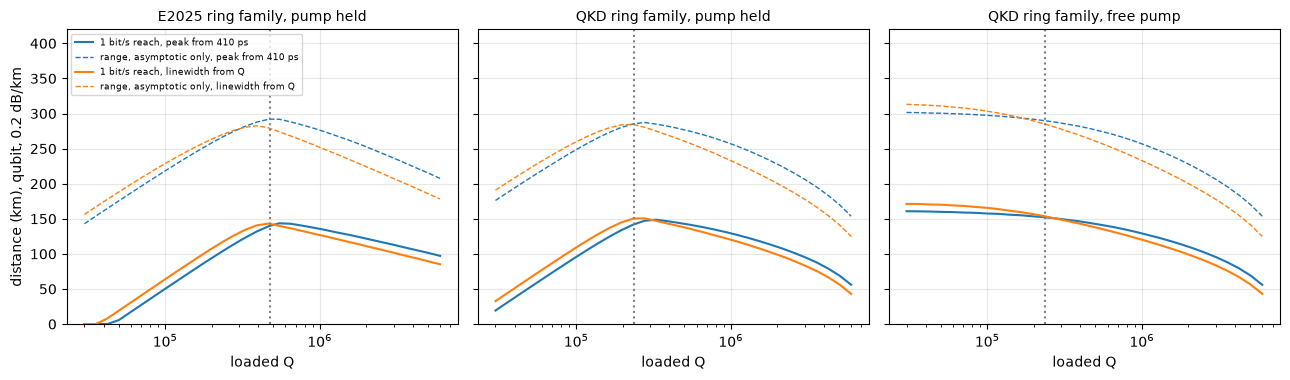

In [12]:
Qs = np.unique(np.concatenate((np.geomspace(3e4, 6e6, 32), [Q_25, Qq])))
q_rows = []
for fam in ("E2025", "QKD"):
    for m in ("peak", "Q"):
        for q_ in Qs:
            if fam == "E2025":
                rel = (q_ / Q_25) ** 3
                dev = Device("E", cal[m], NU_25 / q_, 1.0, lambda d, rel=rel, c_=cal[m]: c_.R * (P_CAP[d] / 3.9) ** 2 * rel)     # ASSUMED: escape unchanged, Q_i is not published
                pols = ("held",)
            else:
                dev = glass(cal[m], q_)
                pols = ("held", "free")
            for pol in pols:
                for d_ in (2, 3):
                    q_rows.append({"fam": fam, "model": m, "Q": float(q_), "pol": pol, "d": d_, **report(dev, R1, d_, "B", pol)})
qsel = lambda fam, m, pol, d_: [r_ for r_ in q_rows if r_["fam"] == fam and r_["model"] == m and r_["pol"] == pol and r_["d"] == d_]
print("family, pump, Q model | best Q | 1 bit/s reach d = 2; d = 3 | range d = 2 with its key rate | Q window for 1 bit/s at 100 km (d = 2), 150 km (d = 3)")
best_Q = {}
for fam, pol in (("E2025", "held"), ("QKD", "held"), ("QKD", "free")):
    for m in ("peak", "Q"):
        r2, r3 = qsel(fam, m, pol, 2), qsel(fam, m, pol, 3)
        Q2 = np.array([r_["Q"] for r_ in r2])
        s25 = np.array([r_["S25"] for r_ in r2])
        rc2, rc3 = np.array([r_["reach_km"] for r_ in r2]), np.array([r_["reach_km"] for r_ in r3])
        ib = int(np.argmax(rc2))
        best_Q[(fam, pol, m)] = float(Q2[int(np.argmax(s25))])
        w100, w150 = np.flatnonzero(rc2 >= 100), np.flatnonzero(rc3 >= 150)
        print(f"  {fam:5s} {pol:4s} {m:4s} | {best_Q[(fam, pol, m)]:.2g} | {rc2[ib]:.0f} km; {rc3.max():.0f} km | {r2[ib]['range_km']:.0f} km at {r2[ib]['S_range']:.0e} bit/s, asymptotic only | "
              + (f"{Q2[w100[0]]:.2g}-{Q2[w100[-1]]:.2g}" if w100.size else "none") + ", " + (f"{Q2[w150[0]]:.2g}-{Q2[w150[-1]]:.2g}" if w150.size else "none"))
# Independent estimate of the optimum from the two scalings
r_un_E = best(replace(E["peak"], Rmax=lambda d: cal["peak"].R * (8.0 / 3.9) ** 2), R1, 2, "B", 0.0)["R"]
q_star_E = Q_25 * (r_un_E / E["peak"].Rmax(2)) ** 0.25
r_un_Q = best(QKD["peak"], R1, 2, "B", 0.0, "free")["R"]
q_star_Q = Qq * (r_un_Q / QKD["peak"].Rmax(2)) ** 0.25
check("best Q, E2025 family: numerical optimum vs Q* from the two scalings (25 %)", best_Q[("E2025", "held", "peak")], q_star_E, 0.25, rel=True)
check("best Q, QKD family: numerical optimum vs Q* from the two scalings (25 %)", best_Q[("QKD", "held", "peak")], q_star_Q, 0.25, rel=True)
# The optimum must lie inside the grids, or the sweep reports the grid and not the physics
for q_ in (Qs[0], Qs[-1]):
    dev_ = Device("E", cal["peak"], NU_25 / q_, 1.0, lambda d, rel=(q_ / Q_25) ** 3: cal["peak"].R * (P_CAP[d] / 3.9) ** 2 * rel)
    b_ = best(dev_, R1, 2, "B", 5.0)
    check(f"optimum inside the grids at Q = {q_:.3g} (1 = yes)", (b_["R"] > dev_.Rmax(2) * R_SCALE[0] * 1.01) and (DT[0] * 1.01 < b_["dt"] < DT[-1] * 0.99), 1.0, 0.0)
lam_, ng_ = s19["pump"]["lam_m"], s19["pump"]["ng"]
beta2 = s19["pump"]["D_lumerical_ps_nm_km"] * 1e-6 * lam_ ** 2 / (2 * np.pi * C_LIGHT)
K_disp = 2 * np.pi * beta2 * C_LIGHT / ng_      # Delta_k = K (k FSR)^2
for s_ in ("1", "2", "5"):
    check(f"Delta_10 from D, scale x{s_}, vs the resonances of notebook 13 (relative)", float(s_) * K_disp * (10 * FSR_K) ** 2, s19["bins_vs_D_scale"][s_]["bins"][-1]["Delta_numeric_Hz"], 0.01, rel=True)
print("Q at half brightness at the band edge: " + ", ".join(f"D x{s_}: {nu_p / (s_ * K_disp * B_SIDE ** 2):.2g}" for s_ in (1, 2, 5)))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (fam, pol, title, qref) in zip(axs, (("E2025", "held", "E2025 ring family, pump held", Q_25), ("QKD", "held", "QKD ring family, pump held", Qq), ("QKD", "free", "QKD ring family, free pump", Qq))):
    for m, col, lab in (("peak", "tab:blue", "peak from 410 ps"), ("Q", "tab:orange", "linewidth from Q")):
        rows_ = qsel(fam, m, pol, 2)
        Qv = [r_["Q"] for r_ in rows_]
        ax.semilogx(Qv, [r_["reach_km"] for r_ in rows_], color=col, label=f"1 bit/s reach, {lab}")
        ax.semilogx(Qv, [r_["range_km"] for r_ in rows_], "--", color=col, lw=1, label=f"range, asymptotic only, {lab}")
    ax.axvline(qref, color="gray", ls=":"); ax.set_title(title, fontsize=10); ax.set_xlabel("loaded Q"); ax.grid(alpha=0.3); ax.set_ylim(0, 420)
axs[0].set_ylabel("distance (km), qubit, 0.2 dB/km"); axs[0].legend(fontsize=6.5, loc="upper left")
fig.tight_layout(); plt.show()

## 11. FSR, dispersion, purity

**FSR:** a shorter ring builds up more field, $R \propto \text{FSR}^2$ at fixed pump, but fewer channels fit in a fixed filter band. **Dispersion:** bins far from the pump dim by the overlap rule. **Purity:** in a QKD link from one source the X interference is of each pair with itself, so purity should matter little. The sweep below is therefore a worst case, $e_{\text{int},X} \to e_{\text{int},X} + ((d-1)/d)(M_\text{ref} - M)$, as if the interference needed independent photons, as in E2024's two rings.

In [13]:
check("channels d = 3 in the band at 21.23 GHz vs paper's 21 after excluding weak channels (30 %)", np.floor(B_SIDE / (3 * FSR_25)), 21.0, 0.3, rel=True)
check("channels d = 2 in the band at 21.23 GHz vs paper's 38 (10 %)", np.floor(B_SIDE / (2 * FSR_25)), 38.0, 0.1, rel=True)
print("FSR sweep, E2025 ring family, rule B, peak model, d = 2")
for fs in (10e9, FSR_25, 30e9, 100e9, FSR_K):
    pen, order = sideband_penalty(fs)
    rel = (fs / FSR_25) ** 2
    dev = Device("E", cal["peak"], G0, 1.0, lambda d, rel=rel: cal["peak"].R * (P_CAP[d] / 3.9) ** 2 * rel, pen)
    avg = replace(dev, Rmax=lambda d, rel=rel: kap * cal["peak"].R * (P_CAP[d] / 3.9) ** 2 * rel)
    ch = int(np.floor(B_SIDE / (2 * fs)))
    r_ = report(dev, R1, 2, "B")
    print(f"  FSR {fs / 1e9:6.1f} GHz, {ch:3d} channels, sideband order {order}: per channel 25 km {r_['S25']:.3g} bit/s, 1 bit/s reach {r_['reach_km']:.0f} km, range {r_['range_km']:.0f} km at {r_['S_range']:.0e} bit/s (asymptotic only); network at 25 km {ch * best(avg, R1, 2, 'B', 25 * KM)['SKR']:.3g} bit/s")

def imbalance_e(bs):
    c_ = np.sqrt(np.asarray(bs, dtype=float))
    d_ = c_.size
    w = np.exp(2j * np.pi / d_)
    pr = np.array([abs(np.sum(c_ * w ** (i * np.arange(d_)))) ** 2 for i in range(d_)])
    return 1 - pr[0] / pr.sum()
bs_t = [0.9, 0.7, 0.5]
ket = sum(np.sqrt(bs_t[k]) * qt.tensor(qt.basis(3, k), qt.basis(3, k)) for k in range(3)).unit()
pr_t = np.array([[abs((qt.tensor(fourier(3, a_), fourier(3, b_, conj=True)).dag() * ket)) ** 2 for b_ in range(3)] for a_ in range(3)])
check("bin imbalance d = 3: closed-form X error vs QuTiP", imbalance_e(bs_t), 1 - np.trace(pr_t) / pr_t.sum(), 1e-9)
K_modes = int(np.floor(B_SIDE / FSR_K))
print(f"\ndispersion on the QKD ring, {K_modes} modes in the band, d = 2, overlap rule")
for scale in (1, 2, 5):
    bs = [1 / (1 + (scale * K_disp * (k * FSR_K) ** 2 / Gq) ** 2) for k in range(1, K_modes + 1)]
    per = []
    for c_ in range(K_modes // 2):
        sel = bs[c_ * 2: (c_ + 1) * 2]
        bm = float(np.mean(sel))
        dv = replace(QKD["peak"], Rmax=lambda d, bm=bm: QKD["peak"].Rmax(d) * bm)
        per.append(report(dv, R1, 2, "B", e_add=imbalance_e(sel)))
    print(f"  D x{scale}: band-edge brightness {bs[-1]:.2f}; band total at 25 km {sum(p['S25'] for p in per):.0f} bit/s; last channel 1 bit/s reach {per[-1]['reach_km']:.0f} km, range {per[-1]['range_km']:.0f} km at {per[-1]['S_range']:.0e} bit/s (asymptotic only)")
print("\npurity, worst case, QKD ring, d = 2; M_ref = 0.921 ASSUMED")
for M_ in (0.80, 0.90, M_REF, 0.98, 1.0):
    print(f"  M = {M_:.3f}: {row_txt(report(QKD['peak'], R1, 2, 'B', e_add=0.5 * (M_REF - M_)))}")
for d_ in Dd:
    ket = phi(d_)
    pure = ket * ket.dag()
    rho = 0.9 * pure + 0.1 * qt.Qobj(np.diag(np.diag(pure.full())), dims=pure.dims)
    check(f"purity as dephasing, d = {d_}, M = 0.9: X QBER of the state vs ((d-1)/d)(1 - M)", state_qber(rho, d_, "X")[0], (d_ - 1) / d_ * 0.1, 1e-9)
print("E2024, with two rings, reports a visibility of 93.3 % after accidental correction and attributes it to source distinguishability: an X error of 3.3 %, part of its fitted 13 %")

PASS  channels d = 3 in the band at 21.23 GHz vs paper's 21 after excluding weak channels (30 %): model = 26, check = 21
PASS  channels d = 2 in the band at 21.23 GHz vs paper's 38 (10 %): model = 40, check = 38
FSR sweep, E2025 ring family, rule B, peak model, d = 2
  FSR   10.0 GHz,  84 channels, sideband order 1: per channel 25 km 63.4 bit/s, 1 bit/s reach 114 km, range 271 km at 3e-07 bit/s (asymptotic only); network at 25 km 3.55e+03 bit/s
  FSR   21.2 GHz,  40 channels, sideband order 1: per channel 25 km 207 bit/s, 1 bit/s reach 140 km, range 292 km at 5e-07 bit/s (asymptotic only); network at 25 km 6.04e+03 bit/s
  FSR   30.0 GHz,  28 channels, sideband order 1: per channel 25 km 286 bit/s, 1 bit/s reach 147 km, range 295 km at 7e-07 bit/s (asymptotic only); network at 25 km 6.65e+03 bit/s
  FSR  100.0 GHz,   8 channels, sideband order 3: per channel 25 km 267 bit/s, 1 bit/s reach 145 km, range 287 km at 7e-07 bit/s (asymptotic only); network at 25 km 2.16e+03 bit/s
  FSR  199.

  D x5: band-edge brightness 0.53; band total at 25 km 797 bit/s; last channel 1 bit/s reach 133 km, range 278 km at 6e-07 bit/s (asymptotic only)

purity, worst case, QKD ring, d = 2; M_ref = 0.921 ASSUMED
  M = 0.800: SKR 0/25/150 km = 339 / 107 / 0.313 [asymptotic only] bit/s; 1 bit/s reach 126 km; range 268 km at 1e-06 bit/s [asymptotic only]
  M = 0.900: SKR 0/25/150 km = 645 / 204 / 0.609 [asymptotic only] bit/s; 1 bit/s reach 139 km; range 283 km at 8e-07 bit/s [asymptotic only]
  M = 0.921: SKR 0/25/150 km = 722 / 228 / 0.684 [asymptotic only] bit/s; 1 bit/s reach 142 km; range 285 km at 8e-07 bit/s [asymptotic only]
  M = 0.980: SKR 0/25/150 km = 979 / 309 / 0.931 [asymptotic only] bit/s; 1 bit/s reach 148 km; range 292 km at 8e-07 bit/s [asymptotic only]
  M = 1.000: SKR 0/25/150 km = 1.07e+03 / 339 / 1.02 bit/s; 1 bit/s reach 150 km; range 294 km at 8e-07 bit/s [asymptotic only]
PASS  purity as dephasing, d = 2, M = 0.9: X QBER of the state vs ((d-1)/d)(1 - M): model = 0.05,

## 12. The best dimension against distance

**Plain words:** a higher dimension carries more bits per photon, but there are more wrong outcomes for accidentals to land on, and each extra output adds dark counts. So there is a crossover, if $e_\text{int}$ does not grow too fast.

The **X-basis loss** also depends on $d$. A single-tone modulator mixes bins through Bessel amplitudes (Jacobi–Anger, as in the Methods of Kues et al. 2017), so equalising $d$ bins onto one channel at the published modulation index $\mu = 1.2$ gives $P = d\,\min_k J_k^2$:

| d | bins mixed | loss at μ = 1.2 | best index |
|---|---|---|---|
| 2 | ±1 | 2 J₁² = 3.04 dB, matching E2025's 3 dB | 1.69 dB at μ = 1.84 |
| 3 | −1, 0, +1 | 3 J₁² = 1.28 dB | 0.46 dB at μ = 1.43 |
| 5 | −2 … +2 | 5 J₂² = 8.96 dB | 3.02 dB at μ = 1.84 |

This is a candidate mechanism for noise and loss growing with $d$. With no equalisation the same weights give crosstalk: a QBER of 8.4 % at $d = 3$ and 39 % at $d = 5$. E2025 measured 8.1 % and 21.4 %, and attributes its $d = 5$ result to the limited modulation index.

In [14]:
for d_, offs in ((3, (-1, 0, 1)), (5, (-2, -1, 0, 1, 2))):
    w = np.exp(2j * np.pi / d_)
    pr = np.array([abs(sum(jv(k, 1.2) ** 2 * w ** (i * j) for j, k in enumerate(offs))) ** 2 for i in range(d_)])
    ket = phi(d_)
    err = tot = 0.0
    for a_ in range(d_):
        for b_ in range(d_):
            pa = sum(jv(offs[k], 1.2) * np.exp(2j * np.pi * a_ * k / d_) * qt.basis(d_, k) for k in range(d_))
            pb = sum(jv(offs[k], 1.2) * np.exp(-2j * np.pi * b_ * k / d_) * qt.basis(d_, k) for k in range(d_))
            p_ = abs((qt.tensor(pa, pb).dag() * ket)) ** 2
            tot += p_
            err += p_ if a_ != b_ else 0.0
    print(f"d = {d_}: X loss {x_eom_dB(d_):.2f} dB at mu = 1.2 (used: {x_ddep(d_):.2f} dB with d = 2 pinned to the fit); crosstalk QBER if not equalised {(1 - pr[0] / pr.sum()) * 100:.1f} %")
    check(f"unequalised crosstalk d = {d_}: closed form vs QuTiP projectors", 1 - pr[0] / pr.sum(), err / tot, 1e-9)
check("d = 3 equal-weight index: J0 = J1 root vs grid optimum", np.linspace(0.2, 3, 2801)[np.argmin([x_eom_dB(3, m_) for m_ in np.linspace(0.2, 3, 2801)])], brentq(lambda m_: jv(0, m_) - jv(1, m_), 1.0, 2.0), 0.002)
check("d = 5 equal-weight index: J0 = J2 root vs grid optimum", np.linspace(0.2, 3, 2801)[np.argmin([x_eom_dB(5, m_) for m_ in np.linspace(0.2, 3, 2801)])], brentq(lambda m_: jv(0, m_) - jv(2, m_), 1.0, 2.5), 0.002)

SAVE_KM = (0, 25, 50, 100, 150, 200, 250, 300)
RULE_TXT = {"A": "same e_int", "B": "fixed white-noise fraction, central", "C": "per-projection background, fitted after seeing the data"}
fine = np.arange(0, 75.01, 0.25)
print("\nbest d against distance, E2025 ring, R1 calibrated, peak model; key rate in bit/s, 'as.' = asymptotic only")
best_table = {}
for rule in ("A", "B", "C"):
    for xm in ("flat", "ddep"):
        rx = Rx("R1", xmode=xm)
        row = []
        for km in SAVE_KM:
            v = {d_: best(E["peak"], rx, d_, rule, km * KM)["SKR"] for d_ in Dd}
            w_ = max(v, key=v.get)
            row.append((km, w_ if v[w_] > 0 else None, v[w_]))
        best_table[(rule, xm)] = row
        print(f"  rule {rule}, {xm:4s}: " + "; ".join(f"{k} km d={w_} {v_:.2g}" + (" as." if 0 < v_ < 1 else "") for k, w_, v_ in row))
    print(f"    rule {rule} = {RULE_TXT[rule]}")
S_flat = {d_: np.array([best(E["peak"], Rx("R1"), d_, "B", a)["SKR"] for a in fine]) for d_ in Dd}
S_ddep = {d_: np.array([best(E["peak"], Rx("R1", xmode="ddep"), d_, "B", a)["SKR"] for a in fine]) for d_ in Dd}
last = lambda m_: float(fine[np.flatnonzero(m_)[-1]] / KM) if np.any(m_) else 0.0
print(f"\nrule B: d = 5 is best up to {last((S_flat[5] > S_flat[3]) & (S_flat[5] > S_flat[2])):.0f} km with flat X loss, {last((S_ddep[5] > S_ddep[3]) & (S_ddep[5] > S_ddep[2])):.0f} km with d-dependent loss")
check("d = 3 / d = 2 crossover, rule B: here vs section 4's sensitivity (0.3 dB)", last(S_flat[3] > S_flat[2]) * KM, [s_[2] for s_ in sens if s_[0] == "rule B"][0], 0.3)
# Sensitivity, not a fit: take the paper's measured d = 5 QBERs at 18 dB as given (its 300 bit/s is not used)
d5_ = evaluate(E["peak"], Rx("R1"), 5, "B", 18.0, np.array([E["peak"].Rmax(5)]))
i5 = np.unravel_index(int(np.argmax(d5_["SKR"])), d5_["SKR"].shape)
ez_m = 0.106 - (float(d5_["e_Z"][i5]) - cal["peak"].e_int("B", 5, "Z"))
ex_m = 0.214 - (float(d5_["e_X"][i5]) - cal["peak"].e_int("B", 5, "X"))
print(f"\nd = 5 at the paper's measured QBERs (10.6 / 21.4 % at 18 dB): e_int,Z = {ez_m:.3f}, e_int,X = {ex_m:.3f}. Sensitivity only, not a fit")
for xm in ("flat", "ddep"):
    print(f"  {xm}: d = 5 measured: {row_txt(report(E['peak'], Rx('R1', xmode=xm, e_Z_val=ez_m, e_X_val=ex_m), 5, 'B'))}")
    print(f"  {xm}: d = 3 rule B:   {row_txt(report(E['peak'], Rx('R1', xmode=xm), 3, 'B'))}")

d = 3: X loss 1.28 dB at mu = 1.2 (used: 1.24 dB with d = 2 pinned to the fit); crosstalk QBER if not equalised 8.4 %
PASS  unequalised crosstalk d = 3: closed form vs QuTiP projectors: model = 0.083504, check = 0.083504
d = 5: X loss 8.96 dB at mu = 1.2 (used: 8.92 dB with d = 2 pinned to the fit); crosstalk QBER if not equalised 39.2 %
PASS  unequalised crosstalk d = 5: closed form vs QuTiP projectors: model = 0.391947, check = 0.391947
PASS  d = 3 equal-weight index: J0 = J1 root vs grid optimum: model = 1.434, check = 1.4347
PASS  d = 5 equal-weight index: J0 = J2 root vs grid optimum: model = 1.841, check = 1.84118

best d against distance, E2025 ring, R1 calibrated, peak model; key rate in bit/s, 'as.' = asymptotic only
  rule A, flat: 0 km d=5 3.8e+03; 25 km d=5 1.2e+03; 50 km d=5 3.8e+02; 100 km d=5 37; 150 km d=5 3.5; 200 km d=5 0.29 as.; 250 km d=5 0.012 as.; 300 km d=None 0
  rule A, ddep: 0 km d=5 3.1e+03; 25 km d=5 9.6e+02; 50 km d=5 3e+02; 100 km d=5 29; 150 km d=5 2.4; 2

  rule C, flat: 0 km d=3 9.2e+02; 25 km d=3 2.9e+02; 50 km d=3 92; 100 km d=3 9; 150 km d=3 0.86 as.; 200 km d=3 0.073 as.; 250 km d=2 0.0038 as.; 300 km d=None 0
  rule C, ddep: 0 km d=3 1.2e+03; 25 km d=3 3.6e+02; 50 km d=3 1.1e+02; 100 km d=3 11; 150 km d=3 1.1; 200 km d=3 0.097 as.; 250 km d=3 0.0057 as.; 300 km d=None 0
    rule C = per-projection background, fitted after seeing the data



rule B: d = 5 is best up to 255 km with flat X loss, 165 km with d-dependent loss
PASS  d = 3 / d = 2 crossover, rule B: here vs section 4's sensitivity (0.3 dB): model = 53.5, check = 53.6

d = 5 at the paper's measured QBERs (10.6 / 21.4 % at 18 dB): e_int,Z = 0.058, e_int,X = 0.165. Sensitivity only, not a fit
  flat: d = 5 measured: SKR 0/25/150 km = 1.19e+03 / 374 / 1.01 bit/s; 1 bit/s reach 150 km; range 246 km at 8e-06 bit/s [asymptotic only]
  flat: d = 3 rule B:   SKR 0/25/150 km = 1.32e+03 / 417 / 1.24 bit/s; 1 bit/s reach 155 km; range 281 km at 2e-06 bit/s [asymptotic only]
  ddep: d = 5 measured: SKR 0/25/150 km = 956 / 299 / 0.578 [asymptotic only] bit/s; 1 bit/s reach 141 km; range 202 km at 4e-05 bit/s [asymptotic only]
  ddep: d = 3 rule B:   SKR 0/25/150 km = 1.65e+03 / 522 / 1.58 bit/s; 1 bit/s reach 160 km; range 291 km at 2e-06 bit/s [asymptotic only]


**So "d = 5 best" under rule B is not a prediction.** At the paper's measured $d = 5$ QBERs, $d = 3$ beats it, and rule C drops $d = 5$ altogether. The X-loss model moves the crossovers without changing the best $d$ at 25 or 150 km under rule B. The $e_\text{int}$ rule matters more. **$d = 3$ is the defensible choice.**

## 13. Receivers

Three receivers, with two limits respected: Z and X cannot act on the same photon, and a passive time-invariant circuit cannot measure the frequency-bin X basis (section 9 checks this: such a circuit gives $|+\rangle$ and $|-\rangle$ the same power per frequency).

| Receiver | What it is |
|---|---|
| **R1** | E2025-like: programmable filter, modulator, filter. X by projection |
| **R2** | R1 with biased bases, $p_Z$ swept 0.5–0.95 |
| **R3** | full $d$-output Fourier sorter, electro-optic, $d$ detectors per basis. ASSUMED X-path loss 3 dB relative to Z, swept 0–6 dB, replacing R1's 3 dB; crosstalk swept from the central $e_{\text{int},X}(d)$ down to $e_{\text{int},X}(2)$ |

**R1 comes in two versions.** E2025's Eq. 6 counts all X projections as if measured in parallel, but its text says the hardware measures one at a time. So:
- **calibrated:** X counted in parallel, as fitted;
- **hardware:** X events divided by $d^2$, one projection per user at a time.

R3 really is parallel, so it is the same in both versions. Dark counts scale with outputs through the $d^2$ accidental sum. R2 can only go as far as X statistics allow: ASSUMED 1000 X events per hour, called "floor" below. With no floor, $p_Z = 0.95$ always wins on paper, with only a few X events per hour at 150 km.

**A time-resolved interferometer** is another X option: the detection is time-varying, so the passive limit does not apply, but timing jitter washes out the beat, $V = e^{-(2\pi\,\delta f\,\sigma)^2/2}$.

**Gap:** R3's loss and crosstalk are assumptions, not a device. It is also assumed to be multi-tone, so the single-tone $d$-dependent X loss does not apply to it, which favours R3 in the d-dependent rows. The floor is a choice, not a finite-key proof.

PASS  R2 at p_Z = 0.5 equals R1 (relative): model = 417.203, check = 417.203
PASS  R3 at 3 dB, same crosstalk, p_Z = 0.5 equals calibrated R1: the fit already counts X in parallel (relative): model = 417.203, check = 417.203
PASS  hardware R1 by hand: (Sigma_Z + Sigma_X/9)/4 x bracket (relative): model = 384.359, check = 384.359
PASS  hardware R1 leaves the QBER unchanged: one projector at a time, same ratio: model = 0.0795238, check = 0.0795238
PASS  dark accidentals at d = 3 vs d^2 D^2 tau (relative): model = 0.00068355, check = 0.00068355
PASS  X events per hour at the floor vs 1000 (relative): model = 1000, check = 1000
winner at each distance, tie = within 1 %; best d in brackets; rule B, E2025 ring, peak model
version                  km            R1          R2          R3  R3 at 0 dB   winner, all d | winner, d <= 3
calibrated, flat         25      931 (d5)2.69e+03 (d5)2.69e+03 (d5)3.08e+03 (d5)   R2 = R3  | R2 = R3
calibrated, flat        150      2.7 (d5)   4.29 (d5)   4.29 

  bias does not change the QBER, so the range is the same for R1 and R2. 1 bit/s reach with best d: R1 170 km, R2 170 km, R3 170 km, R3 best 186 km

break-even X-path loss of R3 against R2 (floor on both), central crosstalk / crosstalk of d = 2:
  calibrated  25 km: d = 2: 3.00 dB / 3.00 dB; d = 3: 3.00 dB / 9.03 dB; d = 5: 3.00 dB / 10.75 dB
  calibrated 150 km: d = 2: 3.00 dB / 3.00 dB; d = 3: 3.00 dB / 3.34 dB; d = 5: 3.00 dB / 3.63 dB
  hardware    25 km: d = 2: 3.73 dB / 3.73 dB; d = 3: 7.64 dB / 9.76 dB; d = 5: 9.70 dB / 11.96 dB
  hardware   150 km: d = 2: 5.28 dB / 5.28 dB; d = 3: 5.77 dB / 7.85 dB; d = 5: 5.78 dB / 8.23 dB
PASS  break-even d = 2, calibrated, same crosstalk: must be R1's own 3 dB (0.01 dB): model = 3, check = 3

time-resolved interferometer, df = 21.23 GHz, d = 2, X loss 3 dB ASSUMED, both outputs read in parallel:
  sigma 3 ps: V = 0.923, adds 3.8 % to e_X: SKR 0/25/150 km = 1.18e+03 / 372 / 0.436 [asymptotic only] bit/s; 1 bit/s reach 138 km; range 281 km at 

  1 bit/s at 25 km needs sigma <= 7.0 ps at df = 21.23 GHz. At FSR 200 GHz, V at 3 ps is 8e-04, so this route needs a low FSR


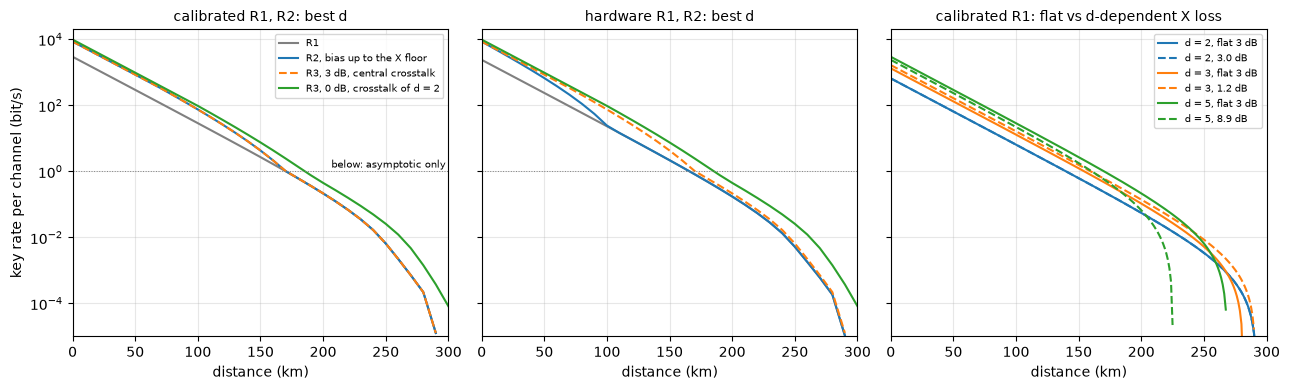

In [15]:
r_1 = best(E["peak"], R1, 3, "B", 5.0)["SKR"]
check("R2 at p_Z = 0.5 equals R1 (relative)", best(E["peak"], Rx("R2", p_Z=0.5), 3, "B", 5.0)["SKR"], r_1, 1e-12, rel=True)
check("R3 at 3 dB, same crosstalk, p_Z = 0.5 equals calibrated R1: the fit already counts X in parallel (relative)", best(E["peak"], Rx("R3", x_L=3.0), 3, "B", 5.0)["SKR"], r_1, 1e-12, rel=True)
o_h = evaluate(E["peak"], Rx("R1", hardware=True), 3, "B", 5.0, np.array([cal["peak"].R]), dt=np.array([300e-12]))
o_c = evaluate(E["peak"], R1, 3, "B", 5.0, np.array([cal["peak"].R]), dt=np.array([300e-12]))
check("hardware R1 by hand: (Sigma_Z + Sigma_X/9)/4 x bracket (relative)", o_h["SKR"][0, 0], float(np.squeeze(0.25 * (o_c["SZ"] + o_c["SX"] / 9) * bracket(o_c["e_Z"], o_c["e_X"], 3, F_25))), 1e-9, rel=True)
check("hardware R1 leaves the QBER unchanged: one projector at a time, same ratio", o_h["e_X"][0, 0], o_c["e_X"][0, 0], 1e-15)
check("dark accidentals at d = 3 vs d^2 D^2 tau (relative)", sums(cal["peak"].R, 1e-12, 1e-12, 620e-12, 0.7, 3, DARK_25)[1], 9 * DARK_25 ** 2 * 620e-12, 1e-3, rel=True)
check("X events per hour at the floor vs 1000 (relative)", best(E["peak"], Rx("R2", floor=True, hardware=True), 2, "B", 25.0)["N_X_h"], 1000.0, 1e-6, rel=True)

ex_c = {d_: cal["peak"].e_int("B", d_, "X") for d_ in Dd}
ex_2 = cal["peak"].e_X
def receivers(version, xm):
    hw = version == "hardware"
    return {"R1": Rx("R1", hardware=hw, xmode=xm), "R2": Rx("R2", floor=True, hardware=hw, xmode=xm), "R3": Rx("R3", floor=True, x_L=R3_L),
            "R3 best": Rx("R3", floor=True, x_L=0.0, e_X_val=ex_2)}
print("winner at each distance, tie = within 1 %; best d in brackets; rule B, E2025 ring, peak model")
print(f"{'version':22s}{'km':>5s}  {'R1':>12s}{'R2':>12s}{'R3':>12s}{'R3 at 0 dB':>12s}   winner, all d | winner, d <= 3")
verdict = {}
for version in ("calibrated", "hardware"):
    for xm in ("flat", "ddep"):
        for km in (25, 150):
            v, vl = {}, {}
            for n_, rx in receivers(version, xm).items():
                vals = {d_: best(E["peak"], rx, d_, "B", km * KM)["SKR"] for d_ in Dd}
                w_ = max(vals, key=vals.get)
                v[n_] = (vals[w_], w_)
                wl = max((2, 3), key=lambda d_: vals[d_])
                vl[n_] = (vals[wl], wl)
            names_ = ("R1", "R2", "R3")
            win = [n_ for n_ in names_ if v[n_][0] >= 0.99 * max(v[x_][0] for x_ in names_)]
            winl = [n_ for n_ in names_ if vl[n_][0] >= 0.99 * max(vl[x_][0] for x_ in names_)]
            verdict[(version, xm, km)] = (v, vl, win, winl)
            print(f"{version + ', ' + xm:22s}{km:5d}  " + "".join(f"{v[n_][0]:7.3g} (d{v[n_][1]})" for n_ in ("R1", "R2", "R3", "R3 best")) + f"   {' = '.join(win):8s} | {' = '.join(winl)}")
print("\nR3 at p_Z = 0.5 against R1, same d:")
for km in (25, 150):
    for d_ in Dd:
        r3v = best(E["peak"], Rx("R3", x_L=3.0), d_, "B", km * KM)["SKR"]
        r1c, r1h = best(E["peak"], R1, d_, "B", km * KM)["SKR"], best(E["peak"], Rx("R1", hardware=True), d_, "B", km * KM)["SKR"]
        print(f"  {km:3d} km, d = {d_}: calibrated x{r3v / r1c:.3f}, hardware x{r3v / r1h:.3f}")
print("\nrange per receiver, d = 2, with its key rate:")
for name, rx in (("R1, R2, R3 at 3 dB", Rx("R1")), ("R3 at 6 dB", Rx("R3", x_L=6.0)), ("R3 at 0 dB, low crosstalk", Rx("R3", x_L=0.0, e_X_val=ex_2))):
    r_ = report(E["peak"], rx, 2, "B")
    print(f"  {name:28s} {r_['range_km']:.0f} km at {r_['S_range']:.0e} bit/s, asymptotic only")
print("  bias does not change the QBER, so the range is the same for R1 and R2. 1 bit/s reach with best d: " + ", ".join(f"{n_} {max(report(E['peak'], rx, d_, 'B')['reach_km'] for d_ in Dd):.0f} km" for n_, rx in receivers("calibrated", "flat").items()))

def r3_skr(L_, d_, a, e_v):
    return best(E["peak"], Rx("R3", floor=True, x_L=L_, e_X_val=e_v), d_, "B", a)["SKR"]
def break_even(tgt, d_, a, e_v, Lmax=20.0):
    if r3_skr(0.0, d_, a, e_v) < tgt:
        return "below it even at 0 dB"
    if r3_skr(Lmax, d_, a, e_v) >= tgt:
        return f"above it even at {Lmax:.0f} dB"
    lo_, hi_ = 0.0, Lmax
    for _ in range(16):
        mid = (lo_ + hi_) / 2
        lo_, hi_ = (mid, hi_) if r3_skr(mid, d_, a, e_v) >= tgt else (lo_, mid)
    return f"{lo_:.2f} dB"
print("\nbreak-even X-path loss of R3 against R2 (floor on both), central crosstalk / crosstalk of d = 2:")
be_store = {}
for version in ("calibrated", "hardware"):
    for km in (25, 150):
        cells = []
        for d_ in Dd:
            tgt = best(E["peak"], Rx("R2", floor=True, hardware=version == "hardware"), d_, "B", km * KM)["SKR"]
            bc, bl = break_even(tgt, d_, km * KM, ex_c[d_]), break_even(tgt, d_, km * KM, ex_2)
            be_store[(version, km, d_)] = (bc, bl)
            cells.append(f"d = {d_}: {bc} / {bl}")
        print(f"  {version:10s} {km:3d} km: " + "; ".join(cells))
check("break-even d = 2, calibrated, same crosstalk: must be R1's own 3 dB (0.01 dB)", float(be_store[("calibrated", 25, 2)][0].split()[0]), 3.0, 0.01)
print("\ntime-resolved interferometer, df = 21.23 GHz, d = 2, X loss 3 dB ASSUMED, both outputs read in parallel:")
for sg in (3e-12, 8e-12, 15e-12):
    V = np.exp(-(2 * np.pi * FSR_25 * sg) ** 2 / 2)
    print(f"  sigma {sg * 1e12:.0f} ps: V = {V:.3f}, adds {(1 - V) / 2 * 100:.1f} % to e_X: {row_txt(report(E['peak'], Rx('TR', floor=True, x_L=3.0), 2, 'B', e_add=0.5 * (1 - V)))}; V >= 0.9 needs df <= {np.sqrt(-2 * np.log(0.9)) / (2 * np.pi * sg) / 1e9:.1f} GHz")
    val = quad(lambda t: np.cos(2 * np.pi * FSR_25 * t) * np.exp(-t ** 2 / (2 * sg ** 2)) / (sg * np.sqrt(2 * np.pi)), -8 * sg, 8 * sg)[0]
    check(f"V at sigma = {sg * 1e12:.0f} ps vs direct average of the beat over Gaussian jitter", V, val, 1e-8)
key_at = lambda sg: best(E["peak"], Rx("TR", floor=True, x_L=3.0), 2, "B", 5.0, e_add=0.5 * (1 - np.exp(-(2 * np.pi * FSR_25 * sg) ** 2 / 2)))["SKR"] - 1.0
print(f"  1 bit/s at 25 km needs sigma <= {brentq(key_at, 1e-12, 8e-12) * 1e12:.1f} ps at df = 21.23 GHz. At FSR 200 GHz, V at 3 ps is {np.exp(-(2 * np.pi * FSR_K * 3e-12) ** 2 / 2):.0e}, so this route needs a low FSR")

kms = np.arange(0, 301, 10.0)
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, version in zip(axs[:2], ("calibrated", "hardware")):
    for n_, col, ls in (("R1", "gray", "-"), ("R2", "tab:blue", "-"), ("R3", "tab:orange", "--"), ("R3 best", "tab:green", "-")):
        rx = receivers(version, "flat")[n_]
        ys = np.array([max(best(E["peak"], rx, d_, "B", km * KM)["SKR"] for d_ in Dd) for km in kms])
        ax.semilogy(kms[ys > 0], ys[ys > 0], color=col, ls=ls, label={"R1": "R1", "R2": "R2, bias up to the X floor", "R3": "R3, 3 dB, central crosstalk", "R3 best": "R3, 0 dB, crosstalk of d = 2"}[n_])
    ax.axhline(1, color="gray", lw=0.7, ls=":"); ax.set_title(f"{version} R1, R2: best d", fontsize=10); ax.set_xlabel("distance (km)"); ax.grid(alpha=0.3); ax.set_xlim(0, 300)
axs[0].set_ylim(1e-5, 2e4); axs[0].set_ylabel("key rate per channel (bit/s)"); axs[0].legend(fontsize=7); axs[0].text(298, 1.3, "below: asymptotic only", fontsize=7, ha="right")
for d_, col in zip(Dd, ("tab:blue", "tab:orange", "tab:green")):
    xk = fine / KM
    axs[2].semilogy(xk[S_flat[d_] > 0], S_flat[d_][S_flat[d_] > 0], color=col, label=f"d = {d_}, flat 3 dB")
    axs[2].semilogy(xk[S_ddep[d_] > 0], S_ddep[d_][S_ddep[d_] > 0], "--", color=col, label=f"d = {d_}, {x_ddep(d_):.1f} dB")
axs[2].set_xlim(0, 300); axs[2].set_title("calibrated R1: flat vs d-dependent X loss", fontsize=10); axs[2].set_xlabel("distance (km)"); axs[2].grid(alpha=0.3); axs[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

**Receiver verdict.**
- **Bias first.** It needs no new hardware and gives a factor of about 2.9 at 25 km.
- **At 25 km** a sorter adds at most about 9 % at its central values with flat X loss, and at $d \le 3$ only 0–3 %. The exception is $d = 5$ in the hardware version with the d-dependent loss, where R2 cannot bias far and R3 wins by a factor of 2.1; that case rests on R3 escaping the single-tone loss.
- **At 150 km** X events are scarce and R2 loses its bias, so R3 gains a factor of 1.5–2.4 wherever X is really counted one projection at a time. In the calibrated version R2 and R3 tie by construction, since the fit already counts X in parallel.
- **The exception:** with the d-dependent loss at $d \le 3$ in the calibrated version, R2 wins at 150 km, because $d = 3$ has only 1.24 dB of X loss against R3's assumed 3 dB.
- **Break-even loss** against R2: 3 dB in the calibrated version, 3.7–9.7 dB at 25 km and 5.3–5.8 dB at 150 km in the hardware version, at central crosstalk. If R3's loss comes on top of R1's 3 dB instead of replacing it, subtract 3 dB.

## Summary

**Fitted vs predicted, E2025 and E2024:**

In [16]:
print(f"{'group':14s}{'quantity':66s}{'model':>10s}{'paper':>10s}{'diff':>9s}  verdict")
for p_ in predictions:
    if p_["group"] != "E2024 strict":
        print(f"{p_['group']:14s}{p_['quantity'][:64]:66s}{p_['model']:10.4g}{p_['paper']:10.4g}{p_['diff']:+8.1f}%  {p_['verdict']}")
st_ = [p_ for p_ in predictions if p_["group"] == "E2024 strict"]
print(f"\nE2024 strict no refit, E2025's e_int moved to another device: {sum(p_['verdict'] == 'MISS' for p_ in st_)} of {len(st_)} QBER values are misses, as expected: e_int is device-specific")
print(f"\ntotal: {sum(p_['verdict'] == 'agrees' for p_ in predictions)} agree, {sum(p_['verdict'] == 'close' for p_ in predictions)} close, {sum(p_['verdict'] == 'MISS' for p_ in predictions)} misses. Predictions are reported as they fall and are not counted as checks.")

group         quantity                                                               model     paper     diff  verdict
E2025         qutrit e_Z                                                           0.05164     0.077   -32.9%  MISS
E2025         qutrit e_X                                                           0.06068     0.081   -25.1%  MISS
E2025         qutrit SKR, best channel (bit/s)                                        1512      1374   +10.0%  close
E2025         qutrit SKR, average channel (bit/s)                                     1059      1024    +3.5%  agrees
E2025         qutrit R_raw (/s), paper value from its own SKR and QBERs               3876      5126   -24.4%  MISS
E2025         qutrit key bracket                                                    0.7802     0.536   +45.5%  MISS
E2025         d = 2: optimal pump (mW), R ~ P^2                                       6.25       3.9   +60.3%  MISS
E2025         d = 2: optimal window (ps)                          

| Result | Value |
|---|---|
| E2025 range | 58.4 dB vs 59 dB, robust, asymptotic only (below 1e-3 bit/s) |
| Heralded g⁽²⁾ | 0.078 vs 0.077, not fitted, the strongest test |
| Qutrit QBER | about 30 % too low: **a miss** |
| Message | sent and decrypted, 37,575-bit key from 200,000 rounds = 60.5 s, f_eff 1.17–1.20 |
| Eve | q = 1: QBER about 28 %, abort. q = 0.2: no abort, marginal key |
| Q rule | best near 5.5 × 10⁵ (E2025 ring) and 3.3 × 10⁵ (QKD ring) at held pump; not as high as possible |
| Dimension | d = 3 is defensible; d = 5 rests on an optimistic rule |
| Receiver | bias first; a sorter helps at long distance |

**Limits:**
- **All key rates are asymptotic.** No finite-key analysis; a range point below 1 bit/s is asymptotic only.
- **Absolute pair rates** are calibrated on E2025 data, never taken from the coupled-mode model (notebook 16). Other devices inherit E2025's loss budget and $e_\text{int}$, and glass-ring pump power is unverified.
- **R3 is an assumption,** not a device: loss, crosstalk, multi-tone drive and active basis choice.
- $e_\text{int}$ is a fitted number. The rate model has no Raman or nonlinear noise beyond $e_\text{int}$, no two-photon absorption and no phase drift along fibre.
- The peak-width puzzle (Q gives 538 ps before jitter, against 410 ps measured with it) is unresolved. The two peak models bracket it.
## Validation summary

Every `check` compared a number with a second method, a closed form or a QuTiP state. Statistical tests use 3 σ.

In [17]:
print(f"runtime {time.time() - t_start:.0f} s")
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with its check"

runtime 35 s
126 of 126 checks passed
